# Who Wrote It? Identifying LLM Families from Their Responses

CMPSC 448 project. This notebook classifies chat responses from the `lmarena-ai/arena-expert-5k` dataset by model family (**Claude**, **GPT**, or **Qwen**) and addresses two research questions:

- **RQ1:** Can the generating model family be identified from the response text?
- **RQ2:** Does including the user's prompt improve identification?

A CNN and a bidirectional LSTM are each trained under three input conditions: input only, output only, and input + output. The full experimental design and its rationale are documented in `DESIGN_DECISIONS.md`. Setup and execution instructions are in `README.md`.

## Setup

The notebook runs locally or on a Google Colab GPU runtime.

- **Colab only:** the first two cells mount Google Drive and set `WHO_WROTE_IT_OUTPUT` to a Drive folder. Skip them when running locally.
- **Packages:** the setup cell installs only packages that are missing. Colab provides PyTorch.
- **Outputs:** all files (logs, checkpoints, test results) are written under `OUTPUT_DIR`. It is taken from `WHO_WROTE_IT_OUTPUT`, with `outputs/` as the default.
- **Persistence:** files on a Colab runtime disk are deleted when the runtime ends, so outputs must be written to a mounted Drive folder. The training controls cell enforces this.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
from pathlib import Path

output_path = Path("/content/drive/MyDrive/CMPSC448_WhoWroteIt")
# The training controls cell verifies that Drive is mounted before any training output is written
os.environ["WHO_WROTE_IT_OUTPUT"] = str(output_path)

print("Outputs will be saved to:", output_path)

Outputs will be saved to: /content/drive/MyDrive/CMPSC448_WhoWroteIt


In [3]:
import importlib.util, os, subprocess, sys, time
from pathlib import Path

# Install only missing packages (PyTorch is preinstalled on Colab; locally it is in .venv)
missing = [pkg for pkg in ["datasets", "pandas", "psutil", "torch"] if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

OUTPUT_DIR = Path(os.environ.get("WHO_WROTE_IT_OUTPUT", "outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = OUTPUT_DIR / "progress_log.txt"

def progress(message):
    """Print immediately and append a timestamped line to the log file."""
    line = f"{time.strftime('%Y-%m-%d %H:%M:%S')} {message}"
    print(line, flush=True)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(line + "\n")

progress(f"Setup done. Output directory: {OUTPUT_DIR.resolve()}")

2026-10-11 21:37:38 Setup done. Output directory: /content/drive/MyDrive/CMPSC448_WhoWroteIt


In [4]:
progress("Loading dataset...")
from datasets import load_dataset

# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("lmarena-ai/arena-expert-5k")

2026-10-11 21:37:42 Loading dataset...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/2.99k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  111MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5128 [00:00<?, ? examples/s]

In [5]:
# Available splits and their sizes
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'model_a', 'model_b', 'winner', 'conversation_a', 'conversation_b', 'evaluation_order', 'full_conversation', 'language', 'occupational_tags'],
        num_rows: 5128
    })
})

In [6]:
# Column names and row count of the train split
train = ds["train"]
print("Columns:", train.column_names)
print("Rows:", train.num_rows)

Columns: ['id', 'model_a', 'model_b', 'winner', 'conversation_a', 'conversation_b', 'evaluation_order', 'full_conversation', 'language', 'occupational_tags']
Rows: 5128


In [7]:
# One example row from the train split
train[0]

{'id': 'f744f0c7-ed1e-43dc-b9b5-d765d2d4ce01',
 'model_a': 'claude-3-5-sonnet-20241022',
 'model_b': 'gemma-3-27b-it',
 'winner': 'both_bad',
 'conversation_a': '[{\'role\': \'user\', \'content\': array([{\'type\': \'text\', \'text\': \'一个长度为n的非负整数序列a，满足单调不降，且所有项的和为S，求符合条件的序列有多少个（n=1000,S=100000）\', \'image\': None, \'mimeType\': None}],\n       dtype=object)}\n {\'role\': \'assistant\', \'content\': array([{\'type\': \'text\', \'text\': \'让我一步步思考这个问题：\\n\\n1) 这是一个组合数学问题，本质上是求将S分成n个非负整数且要求单调不降的方案数\\n\\n2) 这个问题可以转化为将S个球放入n个盒子中，要求每个盒子的球数不少于前一个盒子的球数\\n\\n3) 这个问题有一个经典解法，可以转化为"隔板法"：\\n   - 将S个球排成一行\\n   - 需要放n-1个隔板来分成n份\\n   - 由于要求单调不降，所以每个隔板只能放在"相等或上升"的位置\\n\\n4) 这可以进一步转化为：在S+n-1个位置中选择n-1个位置放隔板\\n   - 总共有S个球和n-1个隔板，共S+n-1个位置\\n   - 需要选择n-1个位置放隔板\\n\\n5) 因此，答案就是组合数C(S+n-1, n-1)\\n\\n6) 代入数据：n=1000, S=100000\\n   答案 = C(100999, 999)\\n\\n这个组合数会是一个非常大的数。由于数值太大，如果需要具体计算可能需要用到大数运算或者取模运算。\\n\\n需要注意的是，这个解法是基于经典的"隔板法"或"插板法"，是一个非常优雅的组合数学解决方案。\', \'image\': None, \'mimeType\': None}],\n       dtype=

## Dataset verification: field types, languages, and models

Checks how the conversation fields are stored and which language labels and model identifiers occur. No rows are parsed or filtered in this section.

In [8]:
# Python types of the conversation fields in the first row, with a short preview
CONV_COLS = ["conversation_a", "conversation_b", "full_conversation"]
row = train[0]
for col in CONV_COLS:
    print(f"{col}: {type(row[col]).__name__}")
    print("  preview:", repr(row[col])[:200])

conversation_a: str
  preview: '[{\'role\': \'user\', \'content\': array([{\'type\': \'text\', \'text\': \'一个长度为n的非负整数序列a，满足单调不降，且所有项的和为S，求符合条件的序列有多少个（n=1000,S=100000）\', \'image\': None, \'mimeType\': None}],\n       dtype=object)
conversation_b: str
  preview: '[{\'role\': \'user\', \'content\': array([{\'type\': \'text\', \'text\': \'一个长度为n的非负整数序列a，满足单调不降，且所有项的和为S，求符合条件的序列有多少个（n=1000,S=100000）\', \'image\': None, \'mimeType\': None}],\n       dtype=object)
full_conversation: str
  preview: '[{\'user\': {\'role\': \'user\', \'content\': array([{\'type\': \'text\', \'text\': \'一个长度为n的非负整数序列a，满足单调不降，且所有项的和为S，求符合条件的序列有多少个（n=1000,S=100000）\', \'image\': None, \'mimeType\': None}],\n       dt


In [9]:
from collections import Counter

# Type consistency across all rows, with counts of missing (None) and empty values
for col in CONV_COLS:
    values = list(train[col])
    types = Counter(type(v).__name__ for v in values)
    missing = sum(v is None for v in values)
    empty = sum(v is not None and len(v) == 0 for v in values)
    print(f"{col}: types={dict(types)}, missing={missing}, empty={empty}")

conversation_a: types={'str': 5128}, missing=0, empty=0
conversation_b: types={'str': 5128}, missing=0, empty=0
full_conversation: types={'str': 5128}, missing=0, empty=0


In [10]:
# Rows per language value
language_counts = Counter(train["language"])
print("Distinct languages:", len(language_counts))
language_counts.most_common()

Distinct languages: 35


[('en', 3032),
 ('zh', 548),
 ('und', 340),
 ('ru', 279),
 ('ja', 277),
 ('pl', 141),
 ('ko', 121),
 ('de', 101),
 ('fr', 52),
 ('fa', 43),
 ('es', 42),
 ('pt', 31),
 ('it', 29),
 ('zh-Hant', 28),
 ('ar', 13),
 ('vi', 6),
 ('<err>', 5),
 ('el', 4),
 ('iw', 4),
 ('tr', 4),
 ('id', 3),
 ('bg', 3),
 ('cs', 3),
 ('uk', 3),
 ('ro', 3),
 ('la', 2),
 ('sk', 2),
 ('sv', 2),
 ('co', 1),
 ('bn', 1),
 ('kha', 1),
 ('gu', 1),
 ('hu', 1),
 ('no', 1),
 ('nl', 1)]

In [11]:
# Model appearances across model_a and model_b combined.
# These count source rows, not usable or unique responses.
model_counts = Counter(list(train["model_a"]) + list(train["model_b"]))
print("Distinct models:", len(model_counts))
model_counts.most_common()

Distinct models: 105


[('claude-opus-4-20250514', 246),
 ('qwen3-235b-a22b-no-thinking', 244),
 ('claude-sonnet-4-20250514', 243),
 ('o3-2025-04-16', 238),
 ('o3-mini', 230),
 ('gpt-4.1-mini-2025-04-14', 230),
 ('o4-mini-2025-04-16', 218),
 ('gpt-4.1-2025-04-14', 218),
 ('deepseek-v3-0324', 211),
 ('claude-3-5-haiku-20241022', 210),
 ('mistral-medium-2505', 208),
 ('chatgpt-4o-latest-20250326-old', 206),
 ('command-a-03-2025', 204),
 ('gemini-2.5-flash-lite-preview-06-17-thinking', 197),
 ('claude-3-5-sonnet-20241022', 194),
 ('llama-4-maverick-17b-128e-instruct', 192),
 ('claude-opus-4-20250514-thinking-16k', 183),
 ('gemma-3-27b-it', 183),
 ('claude-opus-4-1-20250805', 179),
 ('llama-4-scout-17b-16e-instruct', 173),
 ('claude-sonnet-4-20250514-thinking-32k', 171),
 ('kimi-k2-0711-preview', 171),
 ('claude-3-7-sonnet-20250219-thinking-32k', 169),
 ('claude-3-7-sonnet-20250219', 169),
 ('qwen3-235b-a22b-instruct-2507', 162),
 ('grok-3-mini-beta', 159),
 ('mistral-small-3.1-24b-instruct-2503', 155),
 ('llama

## Dataset verification: conversation parsing and attribution (samples)

Three English rows, one each with `evaluation_order` 1, 2, and 3, illustrate how conversations are stored and which model produced each response. These samples motivate the full-dataset checks below; they do not establish rules on their own.

In [12]:
# Optional: schema of the cached source parquet file (no download). Skipped if the cache is unavailable.
INSPECT_LOCAL_CACHE = True
if INSPECT_LOCAL_CACHE:
    try:
        import pyarrow.parquet as pq
        from huggingface_hub import hf_hub_download
        parquet_path = hf_hub_download("lmarena-ai/arena-expert-5k", "data/train-00000-of-00001.parquet",
                                       repo_type="dataset", local_files_only=True)
        schema = pq.read_schema(parquet_path)
        for col in ["model_a", "model_b", "conversation_a", "conversation_b", "evaluation_order", "full_conversation"]:
            print(f"{col}: {schema.field(col).type}")
    except Exception as e:
        print("Skipped local cache inspection:", type(e).__name__)

model_a: string
model_b: string
conversation_a: string
conversation_b: string
evaluation_order: int32
full_conversation: string


In [13]:
# First English row for each evaluation_order 1, 2, 3
langs, orders = train["language"], train["evaluation_order"]
sample_idx = [next(i for i in range(len(train)) if langs[i] == "en" and orders[i] == k) for k in (1, 2, 3)]
for i in sample_idx:
    r = train[i]
    print(i, r["id"], "| order", r["evaluation_order"], "|", r["model_a"], "vs", r["model_b"])

2 63e84dcc-7ddd-42ff-a153-e0d961cc0d03 | order 1 | minimax-m1 vs deepseek-r1-0528
7 9829f6ea-28fb-4568-bdee-62c1350d2eb6 | order 2 | o3-2025-04-16 vs grok-3-mini-beta
53 b8d7e4f8-4dd8-484e-b2df-bdd473a714af | order 3 | o3-2025-04-16 vs command-a-03-2025


The conversation fields are stored as text representations of numpy object arrays, not JSON. Removing the `array(` wrappers by text replacement would be unsafe, because the same characters can occur inside prompts or responses.

`parse_conversation` instead splits each string with Python's `tokenize` module. String literals remain single tokens, so their contents are never modified. The parser then:

1. removes the `array(` and `, dtype=object)` tokens, and converts the exact empty form `array([], dtype=float64)` to `[]`;
2. inserts the comma that numpy omits between consecutive `}` and `{` elements;
3. rejects any other name token (other than `None`, `True`, or `False`) and any `...` truncation marker, rather than repairing them;
4. evaluates the result with `ast.literal_eval`, which accepts only literals and does not execute code.

A final check confirms that every string in the parsed result equals the corresponding original string token.

In [14]:
import ast, io, tokenize

SKIP = (tokenize.NL, tokenize.NEWLINE, tokenize.ENDMARKER)

def parse_conversation(s):
    """Parse one numpy-repr conversation string without executing it."""
    toks = [t for t in tokenize.generate_tokens(io.StringIO(s).readline) if t.type not in SKIP]
    out, i = [], 0
    while i < len(toks):
        t = toks[i]
        if [x.string for x in toks[i:i + 9]] == ["array", "(", "[", "]", ",", "dtype", "=", "float64", ")"]:
            out += ["[", "]"]; i += 9; continue                # exact empty array -> []
        if t.string == "array" and toks[i + 1].string == "(":
            i += 2; continue                                   # drop "array("
        if [x.string for x in toks[i:i + 5]] == [",", "dtype", "=", "object", ")"]:
            i += 5; continue                                   # drop ", dtype=object)"
        if t.type == tokenize.NAME and t.string not in ("None", "True", "False"):
            raise ValueError(f"unexpected name token: {t.string}")
        if t.string == "...":
            raise ValueError("truncation marker found")
        if t.string == "{" and out and out[-1] == "}":
            out.append(",")                                    # missing separator
        out.append(t.string)
        i += 1
    parsed = ast.literal_eval(" ".join(out))
    # Faithfulness check: parsed strings must equal the original string tokens, in order
    originals = [ast.literal_eval(t.string) for t in toks if t.type == tokenize.STRING]
    assert list(all_strings(parsed)) == originals, "text changed during parsing"
    return parsed

def all_strings(o):
    """Yield every string (keys and values) in document order."""
    if isinstance(o, dict):
        for k, v in o.items():
            yield k; yield from all_strings(v)
    elif isinstance(o, list):
        for v in o: yield from all_strings(v)
    elif isinstance(o, str):
        yield o

In [15]:
# Parse the three samples and show their structure
def text_of(msg):
    return msg["content"][0]["text"]

for i in sample_idx:
    r = train[i]
    conv_a, conv_b = parse_conversation(r["conversation_a"]), parse_conversation(r["conversation_b"])
    full = parse_conversation(r["full_conversation"])
    print(f"row {i} (order {r['evaluation_order']}):")
    print("  conversation_a roles:", [m["role"] for m in conv_a], "| conversation_b roles:", [m["role"] for m in conv_b])
    print("  conversation_b extra keys:", sorted(set(conv_b[0]) - set(conv_a[0])))
    print("  full_conversation turns:", len(full), "| keys per turn:", list(full[0].keys()))
    last = full[-1]
    print("  last turn matches conversation_a/b:",
          text_of(last["user"]) == text_of(conv_a[0]) == text_of(conv_b[0]),
          text_of(last["model_a"]) == text_of(conv_a[1]), text_of(last["model_b"]) == text_of(conv_b[1]))

row 2 (order 1):
  conversation_a roles: ['user', 'assistant'] | conversation_b roles: ['user', 'assistant']
  conversation_b extra keys: ['num_tokens']
  full_conversation turns: 1 | keys per turn: ['user', 'model_a', 'model_b']
  last turn matches conversation_a/b: True True True
row 7 (order 2):
  conversation_a roles: ['user', 'assistant'] | conversation_b roles: ['user', 'assistant']
  conversation_b extra keys: ['num_tokens']
  full_conversation turns: 2 | keys per turn: ['user', 'model_a', 'model_b']
  last turn matches conversation_a/b: True True True
row 53 (order 3):
  conversation_a roles: ['user', 'assistant'] | conversation_b roles: ['user', 'assistant']
  conversation_b extra keys: ['num_tokens']
  full_conversation turns: 3 | keys per turn: ['user', 'model_a', 'model_b']
  last turn matches conversation_a/b: True True True


In [16]:
progress("Linking sample history turns to rows...")
# For each history turn of the multi-turn samples, find rows whose *current* turn has the same
# prompt and responses. Lookup only: a cheap substring pre-check, then parsing of candidates.
convs_a = train["conversation_a"]

def rows_with_current_turn(turn):
    prompt = text_of(turn["user"])
    key = repr(prompt[:150])[1:-1]
    hits = []
    for j, s in enumerate(convs_a):
        if key in s[:8000]:
            ca = parse_conversation(s)
            if text_of(ca[0]) == prompt and text_of(ca[1]) == text_of(turn["model_a"]):
                cb = parse_conversation(train[j]["conversation_b"])
                hits.append((j, train[j]["model_a"], train[j]["model_b"], train[j]["evaluation_order"],
                             text_of(cb[1]) == text_of(turn["model_b"])))
    return hits

for i in sample_idx[1:]:
    r = train[i]
    print(f"row {i}: current models {r['model_a']} vs {r['model_b']}")
    for k, turn in enumerate(parse_conversation(r["full_conversation"]), 1):
        print(f"  turn {k}: (row, model_a, model_b, order, model_b response also matches) ->", rows_with_current_turn(turn))

2026-10-11 21:39:04 Linking sample history turns to rows...
row 7: current models o3-2025-04-16 vs grok-3-mini-beta
  turn 1: (row, model_a, model_b, order, model_b response also matches) -> []
  turn 2: (row, model_a, model_b, order, model_b response also matches) -> [(7, 'o3-2025-04-16', 'grok-3-mini-beta', 2, True)]
row 53: current models o3-2025-04-16 vs command-a-03-2025
  turn 1: (row, model_a, model_b, order, model_b response also matches) -> [(2335, 'amazon-nova-experimental-chat-05-14', 'hunyuan-turbos-20250416', 1, True)]
  turn 2: (row, model_a, model_b, order, model_b response also matches) -> []
  turn 3: (row, model_a, model_b, order, model_b response also matches) -> [(53, 'o3-2025-04-16', 'command-a-03-2025', 3, True)]


## Dataset verification: full-dataset parse and structure checks

Parses all three conversation fields for every row and reports failures with their reasons; nothing is repaired or dropped. The checks confirm:
- that the final user–assistant pair matches the last `full_conversation` turn;
- how empty responses are represented;
- that `evaluation_order` is not a turn index.

In [17]:
progress("Parsing all conversation fields...")
# Parse every row of each field; keep successes and failures separately
parsed = {col: {} for col in CONV_COLS}
failures = {col: [] for col in CONV_COLS}
for col in CONV_COLS:
    for i, s in enumerate(train[col]):
        try:
            parsed[col][i] = parse_conversation(s)
        except Exception as e:
            failures[col].append((i, f"{type(e).__name__}: {str(e)[:100]}"))
    print(f"{col}: parsed={len(parsed[col])}, failed={len(failures[col])}")
    for i, reason in failures[col][:3]:
        print(f"  row {i}: {reason}")

2026-10-11 21:39:20 Parsing all conversation fields...
conversation_a: parsed=5128, failed=0
conversation_b: parsed=5128, failed=0
full_conversation: parsed=5128, failed=0


In [18]:
# Message roles, content items per message, and content-item types (current-turn fields + history)
roles, n_items, item_types = Counter(), Counter(), Counter()

def messages(col, conv):
    if col == "full_conversation":
        return [m for turn in conv for m in turn.values()]
    return conv

for col in CONV_COLS:
    for conv in parsed[col].values():
        for m in messages(col, conv):
            roles[(col, m["role"])] += 1
            if m["content"] is None:              # counted, not skipped silently
                n_items[(col, "content=None")] += 1
                continue
            n_items[(col, len(m["content"]))] += 1
            for item in m["content"]:
                item_types[(col, item["type"])] += 1
print("Roles:", dict(roles))
print("Content items per message:", dict(n_items))
print("Content item types:", dict(item_types))

Roles: {('conversation_a', 'user'): 6794, ('conversation_a', 'assistant'): 6794, ('conversation_b', 'user'): 6794, ('conversation_b', 'assistant'): 6794, ('full_conversation', 'user'): 9979, ('full_conversation', 'assistant'): 19958}
Content items per message: {('conversation_a', 1): 13576, ('conversation_a', 0): 10, ('conversation_a', 'content=None'): 2, ('conversation_b', 1): 13573, ('conversation_b', 0): 13, ('conversation_b', 'content=None'): 2, ('full_conversation', 1): 29903, ('full_conversation', 0): 27, ('full_conversation', 'content=None'): 4, ('full_conversation', 3): 2, ('full_conversation', 2): 1}
Content item types: {('conversation_a', 'text'): 13576, ('conversation_b', 'text'): 13573, ('full_conversation', 'text'): 29906, ('full_conversation', 'image'): 5}


In [19]:
# Final-pair checks on rows where all three fields parsed.
# Text is compared separately from metadata (conversation_b messages carry num_tokens; history does not).
def texts(m):
    return None if m["content"] is None else [item.get("text") for item in m["content"]]

def alternates(conv):
    return len(conv) % 2 == 0 and [m["role"] for m in conv] == ["user", "assistant"] * (len(conv) // 2)

both = sorted(set(parsed["conversation_a"]) & set(parsed["conversation_b"]) & set(parsed["full_conversation"]))
checks = {name: [] for name in ["a alternates user/assistant", "b alternates user/assistant", "final prompt a == b",
                                "final pair text == last full turn", "final pair incl. metadata == last full turn",
                                "history length == evaluation_order"]}
for i in both:
    a, b, last = parsed["conversation_a"][i], parsed["conversation_b"][i], parsed["full_conversation"][i][-1]
    results = [
        alternates(a), alternates(b),
        texts(a[-2]) == texts(b[-2]),
        texts(a[-2]) == texts(last["user"]) and texts(a[-1]) == texts(last["model_a"]) and texts(b[-1]) == texts(last["model_b"]),
        a[-2] == last["user"] and a[-1] == last["model_a"] and b[-1] == last["model_b"],
        len(parsed["full_conversation"][i]) == orders[i],
    ]
    for name, ok in zip(checks, results):
        if not ok:
            checks[name].append(i)

print(f"Rows checked: {len(both)}")
for name, bad in checks.items():
    print(f"{name}: {len(both) - len(bad)} pass, {len(bad)} fail; examples: {bad[:5]}")

Rows checked: 5128
a alternates user/assistant: 5128 pass, 0 fail; examples: []
b alternates user/assistant: 5128 pass, 0 fail; examples: []
final prompt a == b: 5128 pass, 0 fail; examples: []
final pair text == last full turn: 5128 pass, 0 fail; examples: []
final pair incl. metadata == last full turn: 0 pass, 5128 fail; examples: [0, 1, 2, 3, 4]
history length == evaluation_order: 4161 pass, 967 fail; examples: [5, 8, 17, 29, 35]


In [20]:
# Empty final prompts/responses, counted by side and reason (counted only; nothing is dropped)
def empty_reason(m):
    if m["content"] is None: return "content=None"
    if len(m["content"]) == 0: return "empty content list"
    if all(not (item.get("text") or "").strip() for item in m["content"]): return "blank text"
    return None

empties = Counter()
for side in ["conversation_a", "conversation_b"]:
    for i, conv in parsed[side].items():
        for part, m in [("prompt", conv[-2]), ("response", conv[-1])]:
            reason = empty_reason(m)
            if reason:
                empties[(side, part, reason)] += 1
for key, n in sorted(empties.items()):
    print(key, n)

('conversation_a', 'response', 'blank text') 1
('conversation_a', 'response', 'content=None') 2
('conversation_a', 'response', 'empty content list') 9
('conversation_b', 'response', 'content=None') 2
('conversation_b', 'response', 'empty content list') 10


### Multi-turn structure

Compares the number of prompt–response pairs in `conversation_a` with the number of turns in `full_conversation`. Only the final pair of each side is used for examples, because the generating models of earlier pairs are not recorded.

In [21]:
# Structural categories: pairs in conversation_a vs turns in full_conversation
def category(i):
    n_pairs, n_full = len(parsed["conversation_a"][i]) // 2, len(parsed["full_conversation"][i])
    if n_pairs == 1:
        return "single pair"
    return "multi pair, = full turns" if n_pairs == n_full else "multi pair, < full turns" if n_pairs < n_full else "multi pair, > full turns"

categories = {}
for i in both:
    categories.setdefault(category(i), []).append(i)
for name, rows in categories.items():
    print(f"{name}: {len(rows)} rows; evaluation_order counts: {dict(sorted(Counter(orders[i] for i in rows).items()))}")

single pair: 4323 rows; evaluation_order counts: {1: 3347, 2: 490, 3: 217, 4: 92, 5: 75, 6: 35, 7: 17, 8: 10, 9: 8, 10: 8, 11: 4, 12: 8, 13: 2, 14: 2, 15: 1, 16: 2, 17: 2, 19: 1, 21: 1, 24: 1}
multi pair, = full turns: 630 rows; evaluation_order counts: {1: 630}
multi pair, < full turns: 175 rows; evaluation_order counts: {2: 103, 3: 38, 4: 14, 5: 5, 6: 5, 7: 2, 8: 3, 9: 3, 11: 1, 17: 1}


In [22]:
# One example per category, plus final-pair text mismatches: compare prompts turn by turn
def show(i):
    a, full = parsed["conversation_a"][i], parsed["full_conversation"][i]
    print(f"row {i} | order {orders[i]} | {train[i]['model_a']} vs {train[i]['model_b']} | "
          f"pairs in a: {len(a) // 2}, full turns: {len(full)}")
    a_prompts = [texts(m)[0][:50] for m in a[::2]]
    full_prompts = [texts(t["user"])[0][:50] for t in full]
    print("  a prompts:   ", a_prompts)
    print("  full prompts:", full_prompts)

for name, rows in categories.items():
    print(f"--- {name}")
    show(rows[0])
print("--- final-pair text mismatches:", len(checks["final pair text == last full turn"]))
for i in checks["final pair text == last full turn"][:3]:
    show(i)

--- single pair
row 0 | order 1 | claude-3-5-sonnet-20241022 vs gemma-3-27b-it | pairs in a: 1, full turns: 1
  a prompts:    ['一个长度为n的非负整数序列a，满足单调不降，且所有项的和为S，求符合条件的序列有多少个（n=1000']
  full prompts: ['一个长度为n的非负整数序列a，满足单调不降，且所有项的和为S，求符合条件的序列有多少个（n=1000']
--- multi pair, = full turns
row 5 | order 1 | claude-3-7-sonnet-20250219-thinking-32k vs qwen3-coder-480b-a35b-instruct | pairs in a: 4, full turns: 4
  a prompts:    ["is a good idea to set 'cron' => ['index' => ['thre", 'But at the moment there is no "cron" entry, so the', 'I experience Server overload\nMemory exhaustion\nDat', 'Magento uses the global default, which is effectiv']
  full prompts: ["is a good idea to set 'cron' => ['index' => ['thre", 'But at the moment there is no "cron" entry, so the', 'I experience Server overload\nMemory exhaustion\nDat', 'Magento uses the global default, which is effectiv']
--- multi pair, < full turns
row 79 | order 2 | llama-4-scout-17b-16e-instruct vs deepseek-v3-0324 | pairs in a: 5, full turns

## Model identifiers and family labels

Counts final responses for each exact model identifier, with a label derived from its naming pattern. Ambiguous identifiers are labeled `needs review` with a reason and are excluded. The curation mapping in the next section includes exactly the identifiers labeled Claude, GPT, or Qwen here.

- **English counts** rely on the dataset's row-level `language == "en"` annotation, which does not guarantee that every final pair is entirely English.
- **All counts** are before deduplication and balancing.

In [23]:
import re
import pandas as pd

def propose(model):
    """Proposed family label and a reason for ambiguous cases."""
    if "-invalid" in model:
        return "needs review", "'-invalid' suffix; meaning undocumented"
    if model.startswith("claude-"):
        return "Claude", ""
    if model.startswith("gpt-oss-"):
        return "needs review", "open-weight OpenAI model, not a GPT chat product"
    if model.startswith(("gpt-", "chatgpt-")):
        return "GPT", ""
    if re.match(r"o\d", model):
        return "needs review", "OpenAI o-series reasoning model, not named GPT"
    if model.startswith("qwq-"):
        return "needs review", "Qwen-team reasoning model, not named qwen-*"
    if model.startswith(("qwen-", "qwen3-")) and "-vl-" in model:
        return "needs review", "Qwen vision-language variant"
    if model.startswith(("qwen-", "qwen3-")):
        return "Qwen", ""
    return "excluded", ""

# Count final responses per model: total, non-empty, and non-empty in "en" rows
counts = Counter()
for side, model_col in [("conversation_a", "model_a"), ("conversation_b", "model_b")]:
    models = train[model_col]
    for i, conv in parsed[side].items():
        m = models[i]
        counts[(m, "total")] += 1
        if empty_reason(conv[-1]) is None:
            counts[(m, "non-empty")] += 1
            if langs[i] == "en":
                counts[(m, "non-empty en")] += 1

model_table = pd.DataFrame(
    [{"model": m, "total": counts[(m, "total")], "non-empty": counts[(m, "non-empty")],
      "non-empty en": counts[(m, "non-empty en")], "proposed": propose(m)[0], "reason": propose(m)[1]}
     for m in sorted({m for m, _ in counts})]
).sort_values(["proposed", "model"]).reset_index(drop=True)

In [24]:
# Identifiers labeled Claude, GPT, or Qwen, and ambiguous identifiers
shown = model_table[model_table["proposed"] != "excluded"]
pd.set_option("display.max_rows", 100)
shown

,model,total,non-empty,non-empty en,proposed,reason
0,claude-3-5-haiku-20241022,210,210,124,Claude,
1,claude-3-5-sonnet-20241022,194,194,130,Claude,
2,claude-3-7-sonnet-20250219,169,169,105,Claude,
3,claude-3-7-sonnet-20250219-thinking-32k,169,169,98,Claude,
4,claude-opus-4-1-20250805,179,179,108,Claude,
5,claude-opus-4-1-20250805-thinking-16k,113,113,63,Claude,
6,claude-opus-4-1-20250805-thinking-16k-old,2,2,2,Claude,
7,claude-opus-4-20250514,246,246,145,Claude,
8,claude-opus-4-20250514-thinking-16k,183,183,109,Claude,
9,claude-sonnet-4-20250514,243,243,129,Claude,


In [25]:
# Totals per proposed label, and a short summary of excluded identifiers
print(model_table.groupby("proposed")[["total", "non-empty", "non-empty en"]].sum())
excluded = model_table[model_table["proposed"] == "excluded"]
print()
print(f"Excluded: {len(excluded)} identifiers, {excluded['total'].sum()} final responses. Name prefixes:")
print(dict(Counter(re.split(r"[-.]", m)[0].lower() for m in excluded["model"]).most_common()))

              total  non-empty  non-empty en
proposed                                    
Claude         1931       1931          1138
GPT            1109       1109           655
Qwen           1351       1349           774
excluded       4805       4797          2856
needs review   1060       1046           631

Excluded: 57 identifiers, 4805 final responses. Name prefixes:
{'deepseek': 8, 'gemini': 8, 'grok': 7, 'glm': 4, 'llama': 4, 'mistral': 4, 'hunyuan': 3, 'mimo': 2, 'amazon': 2, 'gemma': 2, 'kimi': 2, 'step': 2, 'command': 1, 'ibm': 1, 'ling': 1, 'longcat': 1, 'magistral': 1, 'mai': 1, 'minimax': 1, 'nvidia': 1, 'ring': 1}


## Curation

Applies the curation rules:
- an explicit identifier-to-family mapping (13 Claude, 12 GPT, and 13 Qwen identifiers; all others excluded);
- rows labeled exactly `en`;
- the final prompt–response pair from each side;
- exclusion of empty prompts or responses, counted by reason.

Exact duplicate (model, prompt, response) triples are then merged. Each merged example keeps all of its source rows for grouping.

In [26]:
# Identifier-to-family mapping used for curation (identifiers not listed are excluded)
FAMILY_GROUPS = {
    "Claude": ["claude-3-5-haiku-20241022", "claude-3-5-sonnet-20241022", "claude-3-7-sonnet-20250219",
               "claude-3-7-sonnet-20250219-thinking-32k", "claude-opus-4-1-20250805",
               "claude-opus-4-1-20250805-thinking-16k", "claude-opus-4-1-20250805-thinking-16k-old",
               "claude-opus-4-20250514", "claude-opus-4-20250514-thinking-16k", "claude-sonnet-4-20250514",
               "claude-sonnet-4-20250514-thinking-32k", "claude-sonnet-4-5-20250929-old",
               "claude-sonnet-4-5-20250929-thinking-32k"],
    "GPT": ["chatgpt-4o-latest-20250326", "chatgpt-4o-latest-20250326-old", "gpt-4.1-2025-04-14",
            "gpt-4.1-mini-2025-04-14", "gpt-4o-2024-11-20", "gpt-4o-mini-2024-07-18", "gpt-5-chat", "gpt-5-high",
            "gpt-5-high-new-system-prompt", "gpt-5-mini-high", "gpt-5-nano-high", "gpt-5-old"],
    "Qwen": ["qwen-max-2025-01-25", "qwen3-235b-a22b", "qwen3-235b-a22b-instruct-2507", "qwen3-235b-a22b-no-thinking",
             "qwen3-235b-a22b-thinking-2507", "qwen3-30b-a3b", "qwen3-30b-a3b-instruct-2507",
             "qwen3-coder-480b-a35b-instruct", "qwen3-max-2025-09-23", "qwen3-max-2025-09-26", "qwen3-max-preview",
             "qwen3-next-80b-a3b-instruct", "qwen3-next-80b-a3b-thinking"],
}
FAMILY = {m: fam for fam, ms in FAMILY_GROUPS.items() for m in ms}
print({fam: len(ms) for fam, ms in FAMILY_GROUPS.items()})
# Consistency check: the mapping agrees with the labeling rules above, and every identifier occurs in the data
assert all(propose(m)[0] == fam for m, fam in FAMILY.items()), "mapping differs from reviewed proposal"
assert set(FAMILY) <= set(model_table["model"])

{'Claude': 13, 'GPT': 12, 'Qwen': 13}


In [27]:
# Extract the final pair from each eligible side; count exclusions by reason
def single_text(m):
    """Text of a message with exactly one text item, else None."""
    c = m["content"]
    return c[0]["text"] if c and len(c) == 1 and c[0]["type"] == "text" else None

records, excluded_pairs = [], Counter()
for side, model_col in [("conversation_a", "model_a"), ("conversation_b", "model_b")]:
    models = train[model_col]
    for i, conv in parsed[side].items():
        model = models[i]
        if model not in FAMILY or langs[i] != "en":
            continue
        prompt_msg, response_msg = conv[-2], conv[-1]
        reason = None
        if empty_reason(prompt_msg):
            reason = "empty prompt: " + empty_reason(prompt_msg)
        elif empty_reason(response_msg):
            reason = "empty response: " + empty_reason(response_msg)
        elif single_text(prompt_msg) is None or single_text(response_msg) is None:
            reason = "not a single text item"
        if reason:
            excluded_pairs[(FAMILY[model], side, reason)] += 1
            continue
        records.append({"row": i, "id": train[i]["id"], "side": side[-1], "model": model, "family": FAMILY[model],
                        "prompt": single_text(prompt_msg), "response": single_text(response_msg)})

pairs = pd.DataFrame(records)
print("Eligible non-empty pairs:", len(pairs))
print("Excluded:", dict(excluded_pairs) or "none")

Eligible non-empty pairs: 2567
Excluded: {('Qwen', 'conversation_b', 'empty response: content=None'): 1}


In [28]:
# Deduplicate exact (model, prompt, response) triples, keeping all source rows/sides for later grouping
deduped = (pairs.groupby(["model", "prompt", "response"], sort=False)
                .agg(family=("family", "first"), rows=("row", list), ids=("id", list), sides=("side", list))
                .reset_index())
deduped["n_sources"] = deduped["rows"].map(len)

print(pd.DataFrame({"before dedup": pairs["family"].value_counts(), "after dedup": deduped["family"].value_counts()}))
print("Triples with more than one source:", (deduped["n_sources"] > 1).sum())

        before dedup  after dedup
family                           
Claude          1138         1138
Qwen             774          774
GPT              655          654
Triples with more than one source: 1


In [29]:
# Preliminary whitespace word counts (not the final tokenizer)
deduped["prompt_words"] = deduped["prompt"].str.split().str.len()
deduped["response_words"] = deduped["response"].str.split().str.len()
deduped.groupby("family")[["prompt_words", "response_words"]].describe(percentiles=[0.5, 0.9, 0.99]).round(0).T

family                Claude      GPT    Qwen
prompt_words   count  1138.0    654.0   774.0
               mean    256.0    274.0   221.0
               std     579.0    628.0   413.0
               min       1.0      1.0     1.0
               50%      67.0     70.0    62.0
               90%     599.0    716.0   601.0
               99%    2840.0   2968.0  2455.0
               max    7282.0   8940.0  3398.0
response_words count  1138.0    654.0   774.0
               mean    484.0    715.0   874.0
               std     510.0   1018.0   735.0
               min       1.0      1.0     1.0
               50%     318.0    574.0   731.0
               90%    1004.0   1194.0  1582.0
               99%    2591.0   2743.0  3279.0
               max    5221.0  22725.0  9175.0

## Grouping related rows

Prevents related conversations and repeated prompts from crossing splits:
- rows that share any exact, non-empty user prompt (from history or current fields) are connected;
- connections are merged transitively (union-find);
- all source rows are used, including rows excluded during curation, so that indirect links are kept;
- each group's ID is its smallest source row index.

In [30]:
progress("Grouping rows by shared prompts...")
# Exact non-empty user prompt texts per source row (history + current fields, no normalization)
def user_prompts(i):
    msgs = [m for side in ["conversation_a", "conversation_b"] for m in parsed[side][i]]
    msgs += [turn["user"] for turn in parsed["full_conversation"][i]]
    return {item["text"] for m in msgs if m["role"] == "user" and m["content"]
            for item in m["content"] if item["type"] == "text" and item["text"].strip()}

row_prompts = {i: user_prompts(i) for i in range(len(train))}

# Union-find: link every row to the first row seen with the same prompt
parent = list(range(len(train)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(x, y):
    rx, ry = find(x), find(y)
    if rx != ry:
        parent[max(rx, ry)] = min(rx, ry)   # root is always the smaller index

first_row = {}
for i, prompts in row_prompts.items():
    for text in prompts:
        union(i, first_row.setdefault(text, i))

group_of = [find(i) for i in range(len(train))]   # group ID = smallest row index in the group
group_sizes = Counter(group_of)
print("Source rows:", len(train), "| groups:", len(group_sizes))

2026-10-11 21:41:16 Grouping rows by shared prompts...
Source rows: 5128 | groups: 4622


In [31]:
# Checks: each prompt lies in exactly one group; every curated example's sources share one group
prompt_groups = {}
for i, prompts in row_prompts.items():
    for text in prompts:
        prompt_groups.setdefault(text, set()).add(group_of[i])
print("Prompts in more than one group:", sum(len(g) > 1 for g in prompt_groups.values()))

source_groups = deduped["rows"].map(lambda rows: {group_of[r] for r in rows})
print("Curated examples whose sources span several groups:", (source_groups.map(len) != 1).sum())
deduped["group"] = source_groups.map(min)
print("Curated examples without a group:", deduped["group"].isna().sum())

Prompts in more than one group: 0
Curated examples whose sources span several groups: 0
Curated examples without a group: 0


In [32]:
# Group sizes in the curated data, and the five largest represented groups
per_group = deduped.groupby("group").size()
print("Groups represented in curated data:", len(per_group))
print("Curated examples per group: median", per_group.median(), "| 90th pct", per_group.quantile(0.9),
      "| max", per_group.max())
largest = per_group.sort_values(ascending=False).head(5).index
summary = deduped[deduped["group"].isin(largest)].groupby(["group", "family"]).size().unstack(fill_value=0)
summary.insert(0, "source rows", [group_sizes[g] for g in summary.index])
summary.loc[largest]

Groups represented in curated data: 1895
Curated examples per group: median 1.0 | 90th pct 2.0 | max 7


family,source rows,Claude,GPT,Qwen
group,,,,
342,6,3,0,4
1321,5,3,3,0
475,5,1,5,0
147,5,4,0,2
306,6,0,1,4


In [33]:
# Check for large merges caused by generic prompts: largest group and most widely shared prompts
print("Largest group (source rows):", max(group_sizes.values()))
rows_per_prompt = Counter(text for prompts in row_prompts.values() for text in prompts)
for text, n_rows in rows_per_prompt.most_common(8):
    group = group_of[first_row[text]]
    print(f"{n_rows:3d} rows | group {group} ({group_sizes[group]} rows) | {text[:60]!r}")

Largest group (source rows): 6
  6 rows | group 342 (6 rows) | 'Generate a research problem for a Master thesis project on a'
  6 rows | group 342 (6 rows) | 'Generate three minor modifications of the research problem D'
  6 rows | group 342 (6 rows) | "I'm a Master of Theology student writing a thesis on the top"
  6 rows | group 701 (6 rows) | 'RandomForestClassifier的criterion选择entropy时是ID3还是C4.5？'
  6 rows | group 701 (6 rows) | '随机森林对子集进行有放回的抽样，在采集单个子集的时候，元素也是有放回到的吗？'
  5 rows | group 147 (5 rows) | 'Find the shortest string (in character count) that overflows'
  5 rows | group 342 (6 rows) | 'Analyze these research problems,\n1. "Despite the theological'
  5 rows | group 342 (6 rows) | 'Analyze the research problems,\n\n1. "Despite the theological '


## Balancing and grouped split

**Balancing.** All 654 GPT examples are kept. 654 Claude and 654 Qwen examples are sampled without replacement (seed 42) from a stable ordering, for 1,962 examples in total. Downsampling discards 604 usable examples. Group IDs are assigned before sampling and are not recomputed.

**Split.** Whole groups are assigned to train, validation, and test (target 80/10/10 per family) in one deterministic greedy pass:
1. The represented groups are shuffled with seed 42, then sorted largest first; the shuffle only breaks ties.
2. Each group goes to the split with the greatest relative shortfall for the group's families. Shortfall is the gap between the current count and the target, divided by the target.

Only example counts and family labels are used. The same assignment is used for all six configurations and is checked against `split_reference.csv`.

In [34]:
import random

SEED, PER_FAMILY = 42, 654

# Stable ordering (independent of dict/groupby order), then sample per family
stable = (deduped.assign(first_row=deduped["rows"].map(min), first_side=deduped["sides"].map(min))
            .sort_values(["family", "first_row", "first_side", "model"]).reset_index(drop=True))
balanced = pd.concat([stable[stable["family"] == fam].sample(n=PER_FAMILY, replace=False, random_state=SEED)
                      for fam in ["Claude", "GPT", "Qwen"]]).reset_index(drop=True)
print(balanced["family"].value_counts().to_dict(), "| total", len(balanced))
assert (balanced["family"].value_counts() == PER_FAMILY).all()

{'Claude': 654, 'GPT': 654, 'Qwen': 654} | total 1962


In [35]:
# Greedy whole-group assignment toward 80/10/10 per family
SPLITS = {"train": 0.8, "val": 0.1, "test": 0.1}
FAMILIES = ["Claude", "GPT", "Qwen"]
target = {s: {f: frac * PER_FAMILY for f in FAMILIES} for s, frac in SPLITS.items()}
current = {s: Counter() for s in SPLITS}

group_counts = pd.crosstab(balanced["group"], balanced["family"])   # group x family example counts
groups = sorted(group_counts.index)
random.Random(SEED).shuffle(groups)
groups.sort(key=lambda g: -group_counts.loc[g].sum())    # stable sort: largest first, shuffled ties

split_of_group = {}
for g in groups:
    counts = group_counts.loc[g]
    need = {s: sum(counts[f] * (target[s][f] - current[s][f]) / target[s][f] for f in FAMILIES) for s in SPLITS}
    best = max(SPLITS, key=lambda s: need[s])              # ties: first in train/val/test order
    split_of_group[g] = best
    current[best].update({f: counts[f] for f in FAMILIES})

balanced["split"] = balanced["group"].map(split_of_group)

In [36]:
# Results: per-split, per-family counts, deviation from target, and represented groups
table = balanced.groupby(["split", "family"]).size().unstack().loc[list(SPLITS)]
table["total"] = table.sum(axis=1)
table["groups"] = balanced.groupby("split")["group"].nunique()
table["share"] = (table["total"] / len(balanced)).round(3)
print(table)
print("Deviation from per-family target:")
print((table[FAMILIES] - pd.DataFrame(target).T.loc[list(SPLITS), FAMILIES]).round(1))

family  Claude  GPT  Qwen  total  groups  share
split                                          
train      522  522   522   1566    1238  0.798
val         66   66    66    198     155  0.101
test        66   66    66    198     156  0.101
Deviation from per-family target:
family  Claude  GPT  Qwen
split                    
train     -1.2 -1.2  -1.2
val        0.6  0.6   0.6
test       0.6  0.6   0.6


In [37]:
# Verification
assert balanced["split"].notna().all() and len(balanced) == 3 * PER_FAMILY      # every example assigned once
assert (balanced.groupby("group")["split"].nunique() == 1).all()                 # no group crosses splits
assert not balanced.duplicated(["model", "prompt", "response"]).any()           # no example appears twice

prompt_splits = {}
for rows, split in zip(balanced["rows"], balanced["split"]):
    for r in rows:
        for text in row_prompts[r]:
            prompt_splits.setdefault(text, set()).add(split)
assert all(len(s) == 1 for s in prompt_splits.values())                         # no prompt crosses splits
assert all(set(balanced[balanced["split"] == s]["family"]) == set(FAMILIES) for s in SPLITS)
print("All checks passed. Prompts checked:", len(prompt_splits))

All checks passed. Prompts checked: 2766


In [39]:
# Compact reference of the selected examples and their split assignments (split_reference.csv).
# Each run must reproduce it exactly; creating it requires INITIALIZE_SPLIT_REFERENCE = True.
# On a remote runtime, the file must be uploaded alongside the notebook.
import hashlib
REFERENCE_FILE = Path("split_reference.csv")
INITIALIZE_SPLIT_REFERENCE = False   # True only to create the reference file for the first time

reference = pd.DataFrame({
    "ids": balanced["ids"].map(lambda ids: "|".join(sorted(ids))),
    "model": balanced["model"],
    "text_sha1": [hashlib.sha1((p + "\x00" + r).encode("utf-8")).hexdigest()
                  for p, r in zip(balanced["prompt"], balanced["response"])],
    "split": balanced["split"],
}).sort_values(["ids", "model"]).reset_index(drop=True)

if REFERENCE_FILE.exists():
    saved = pd.read_csv(REFERENCE_FILE)
    assert saved.equals(reference), "Selected examples or split assignments differ from split_reference.csv"
    print("Split reference reproduced exactly:", len(reference), "examples")
elif INITIALIZE_SPLIT_REFERENCE:
    reference.to_csv(REFERENCE_FILE, index=False)
    print("Wrote", REFERENCE_FILE, "with", len(reference), "examples")
else:
    raise FileNotFoundError(f"{REFERENCE_FILE} is missing; place it next to the notebook "
                            "(or set INITIALIZE_SPLIT_REFERENCE = True to create it deliberately).")

Split reference reproduced exactly: 1962 examples


## Tokenization and sequence lengths

The tokenizer uses only Python's `re` module:
- case is preserved;
- each word sequence (`\w+`) is one token;
- each punctuation character (`[^\w\s]`) is one token;
- each line break (CRLF or LF) becomes `<nl>`;
- all other whitespace, including spaces and indentation, is discarded.

`\w` is Unicode-aware, so a run of CJK characters forms a single token. For the input + output condition, `<sep>` separates the prompt and response tokens. Sequences are not truncated.

In [40]:
import re

NL, SEP, PAD, UNK = "<nl>", "<sep>", "<pad>", "<unk>"
TOKEN_RE = re.compile(r"\r\n|\n|\w+|[^\w\s]")

def tokenize(text):
    return [NL if t in ("\r\n", "\n") else t for t in TOKEN_RE.findall(text)]

def input_tokens(row, condition):
    if condition == "input":
        return tokenize(row["prompt"])
    if condition == "output":
        return tokenize(row["response"])
    return tokenize(row["prompt"]) + [SEP] + tokenize(row["response"])

example = "Don't PANIC!\r\ndef f(x):\n    return x**2  # it's 4.5"
print(tokenize(example))
# Literal "<sep>"/"<nl>" text is split into "<", "sep", ">", so it can never equal a special token
print(tokenize("<sep> <nl>"))
assert not {NL, SEP, PAD, UNK} & set(tokenize("<sep> <nl> <pad> <unk>"))

['Don', "'", 't', 'PANIC', '!', '<nl>', 'def', 'f', '(', 'x', ')', ':', '<nl>', 'return', 'x', '*', '*', '2', '#', 'it', "'", 's', '4', '.', '5']
['<', 'sep', '>', '<', 'nl', '>']


In [41]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
Tesla T4


In [42]:
progress("Measuring token lengths...")
# Token-length percentiles per split and input condition (complete sequences, no truncation)
length_rows = []
for split in SPLITS:
    part = balanced[balanced["split"] == split]
    for condition in ["input", "output", "input + output"]:
        lengths = pd.Series([len(input_tokens(r, condition)) for _, r in part.iterrows()])
        length_rows.append({"split": split, "condition": condition, "median": lengths.median(),
                            "p90": lengths.quantile(0.9), "p95": lengths.quantile(0.95),
                            "p99": lengths.quantile(0.99), "max": lengths.max()})
pd.DataFrame(length_rows).set_index(["split", "condition"]).round(0)

2026-10-11 21:42:52 Measuring token lengths...


median     p90     p95      p99    max
split condition                                             
train input             90.0  1312.0  2575.0   7194.0  13343
      output          1040.0  2734.0  3830.0   9974.0  41277
      input + output  1280.0  4054.0  6252.0  12275.0  41447
val   input            136.0  1488.0  2527.0   5953.0   9131
      output          1070.0  3077.0  4098.0   6070.0   7324
      input + output  1336.0  4279.0  6065.0   9096.0   9999
test  input            100.0  1120.0  2231.0   7472.0  20150
      output           960.0  2494.0  3011.0   4504.0   5141
      input + output  1172.0  3268.0  5404.0   8380.0  21368

In [43]:
progress("Counting training vocabulary...")
# Vocabulary size from training prompts and responses only (no cap; the lookup table is built in a later cell)
train_part = balanced[balanced["split"] == "train"]
train_vocab = Counter(t for text in pd.concat([train_part["prompt"], train_part["response"]]) for t in tokenize(text))
print("Training distinct tokens:", len(train_vocab), "| appearing once:", sum(c == 1 for c in train_vocab.values()))

2026-10-11 21:43:00 Counting training vocabulary...
Training distinct tokens: 90128 | appearing once: 33947


## Vocabulary, batching, models, and compute benchmark

- **Vocabulary:** built from training prompts and responses only, with no size cap (90,131 entries, including `<pad>`, `<unk>`, `<nl>`, and `<sep>`).
- **Batching:** each batch is padded to its longest sequence, with a minimum of 5 tokens (the largest CNN window).
- **CNN:**
  - 128-dimensional embeddings;
  - convolutions with windows 2–5 and 128 filters each;
  - ReLU, then global max pooling over valid positions only.
- **BiLSTM:**
  - 128-dimensional embeddings;
  - one bidirectional layer with 128 units per direction over packed sequences;
  - the final forward and backward states are concatenated.
- **Classifier:** both models apply dropout 0.5 before a three-class linear classifier.

The benchmark times a warm-up step and three training steps on fixed input + output training batches. The saved benchmark outputs come from a Colab Tesla T4 run with the longer cases enabled; `RUN_LONGER_CASES` is now `False`. These timings measure compute cost only and say nothing about classification performance.

In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence

LABELS = {"Claude": 0, "GPT": 1, "Qwen": 2}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
progress(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

# Vocabulary from training prompts and responses only (full, no cap); special tokens first
itos = [PAD, UNK, NL, SEP] + [t for t, _ in train_vocab.most_common() if t != NL]
stoi = {t: i for i, t in enumerate(itos)}
PAD_ID, UNK_ID = stoi[PAD], stoi[UNK]
print("Vocabulary size (incl. specials):", len(itos))

def encode(tokens):
    return [stoi.get(t, UNK_ID) for t in tokens]

def pad_batch(seqs, labels, min_len=5):
    """Pad encoded sequences to the longest in the batch (at least min_len = largest CNN window)."""
    lengths = torch.tensor([len(s) for s in seqs])
    width = max(int(lengths.max()), min_len)
    ids = torch.full((len(seqs), width), PAD_ID)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s)
    return ids, lengths, torch.tensor(labels)      # lengths stay on CPU (required by pack_padded_sequence)

def make_batch(rows, condition, min_len=5):
    seqs = [encode(input_tokens(r, condition)) for _, r in rows.iterrows()]
    return pad_batch(seqs, [LABELS[f] for f in rows["family"]], min_len)

2026-10-11 21:43:14 Device: cuda (Tesla T4)
Vocabulary size (incl. specials): 90131


In [45]:
EMB_DIM, N_CLASSES = 128, 3

class TextCNN(nn.Module):
    """Parallel convolutions (windows 2-5, 128 filters each) + ReLU + masked global max pooling."""
    def __init__(self, vocab_size, windows=(2, 3, 4, 5), filters=128, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMB_DIM, padding_idx=PAD_ID)
        self.convs = nn.ModuleList(nn.Conv1d(EMB_DIM, filters, k) for k in windows)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(filters * len(windows), N_CLASSES)

    def forward(self, ids, lengths):
        x = self.embedding(ids).transpose(1, 2)              # (batch, emb, time)
        pooled = []
        for conv in self.convs:
            h = F.relu(conv(x))                              # (batch, filters, time - k + 1)
            k = conv.kernel_size[0]
            # Only windows that start inside the text are pooled. A text shorter than k keeps
            # its first window, whose padding positions embed to zero (padding_idx).
            n_valid = (lengths.to(h.device) - k + 1).clamp(min=1)
            mask = torch.arange(h.size(2), device=h.device)[None, :] < n_valid[:, None]
            pooled.append(h.masked_fill(~mask[:, None, :], float("-inf")).max(dim=2).values)
        return self.fc(self.dropout(torch.cat(pooled, dim=1)))

class BiLSTM(nn.Module):
    """One-layer bidirectional LSTM (128 per direction) over packed sequences."""
    def __init__(self, vocab_size, hidden=128, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMB_DIM, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(EMB_DIM, hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden, N_CLASSES)

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(self.embedding(ids), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        final = torch.cat([h_n[-2], h_n[-1]], dim=1)          # final forward and backward states
        return self.fc(self.dropout(final))

# Correctness check: a 1-token text gives the same output whether batched with padding or alone,
# so padding does not leak into either model
torch.manual_seed(SEED)
for Model in (TextCNN, BiLSTM):
    m = Model(len(itos)).eval()
    padded = m(torch.tensor([[5, PAD_ID, PAD_ID, PAD_ID, PAD_ID], [5, 6, 7, 8, 9]]), torch.tensor([1, 5]))[0]
    alone = m(torch.tensor([[5, PAD_ID, PAD_ID, PAD_ID, PAD_ID]]), torch.tensor([1]))[0]
    longer = m(torch.tensor([[5] + [PAD_ID] * 20]), torch.tensor([1]))[0]
    print(Model.__name__, "padding-invariant:", torch.allclose(padded, alone) and torch.allclose(alone, longer))

TextCNN padding-invariant: True
BiLSTM padding-invariant: True


In [47]:
import psutil

BENCH_LOG = OUTPUT_DIR / "benchmark_log.txt"
print("Torch CPU threads:", torch.get_num_threads(), "| logical CPUs:", psutil.cpu_count())
print(f"RAM total {psutil.virtual_memory().total / 2**30:.1f} GB, available {psutil.virtual_memory().available / 2**30:.1f} GB")

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def log_bench(message):
    progress(message)
    with open(BENCH_LOG, "a", encoding="utf-8") as f:
        f.write(f"{time.strftime('%Y-%m-%d %H:%M:%S')} {message}\n")

def benchmark(Model, rows, name, steps=3, max_step_seconds=120):
    """One warm-up step, then time `steps` forward/backward/optimizer steps on one fixed batch."""
    torch.manual_seed(SEED)
    model = Model(len(itos)).to(DEVICE).train()
    optimizer = torch.optim.Adam(model.parameters())
    ids, lengths, labels = make_batch(rows, "input + output")
    ids, labels = ids.to(DEVICE), labels.to(DEVICE)          # lengths stay on CPU
    padding = round(100 * (1 - lengths.sum().item() / ids.numel()), 1)
    log_bench(f"START {Model.__name__} | {name} | batch {len(rows)} | max_len {ids.size(1)} | padding {padding}% | {DEVICE}")
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    times = []
    for step in range(steps + 1):                         # step 0 = warm-up (not timed)
        sync(); start = time.perf_counter()
        optimizer.zero_grad()
        loss = F.cross_entropy(model(ids, lengths), labels)
        loss.backward()
        optimizer.step()
        sync(); elapsed = time.perf_counter() - start
        log_bench(f"  step {step}{' (warm-up)' if step == 0 else ''}: {elapsed:.2f} s")
        if step > 0:
            times.append(elapsed)
        if elapsed > max_step_seconds:                    # stop early if a step is too slow
            log_bench("  stopped: step exceeded time limit")
            break
    result = {"model": Model.__name__, "batch rows": name, "batch": len(rows), "max_len": ids.size(1),
              "padding %": padding, "sec/step": round(sum(times) / len(times), 3) if times else None,
              "timed steps": len(times), "device": str(DEVICE)}
    if DEVICE.type == "cuda":
        result["GPU peak GB (measured)"] = round(torch.cuda.max_memory_allocated() / 2**30, 2)
    log_bench(f"DONE {result}")
    return result

# Input + output lengths of training examples, for choosing benchmark batches
train_part = balanced[balanced["split"] == "train"].copy()
train_part["io_len"] = [len(input_tokens(r, "input + output")) for _, r in train_part.iterrows()]
by_len = train_part.sort_values("io_len")

def near(q, n):
    """n training examples with lengths around quantile q."""
    centre = int(q * (len(by_len) - 1))
    lo = min(max(centre - n // 2, 0), len(by_len) - n)
    return by_len.iloc[lo:lo + n]

Torch CPU threads: 1 | logical CPUs: 2
RAM total 12.7 GB, available 10.1 GB


In [48]:
# Benchmarks. By default only the median-length batch-16 case runs; RUN_LONGER_CASES adds the
# p90 batch-16 case and the p99 and maximum-length batch-1 cases.
RUN_LONGER_CASES = False
plan = [("median", near(0.5, 16))]
if RUN_LONGER_CASES:
    plan += [("p90", near(0.9, 16)), ("p99, batch 1", near(0.99, 1)), ("max, batch 1", by_len.tail(1))]

results = []
for name, rows in plan:
    for Model in (TextCNN, BiLSTM):
        results.append(benchmark(Model, rows, name))
bench = pd.DataFrame(results)
bench

2026-10-11 21:43:53 START TextCNN | median | batch 16 | max_len 1285 | padding 0.5% | cuda
2026-10-11 21:43:56   step 0 (warm-up): 2.73 s
2026-10-11 21:43:56   step 1: 0.03 s
2026-10-11 21:43:56   step 2: 0.03 s
2026-10-11 21:43:56   step 3: 0.03 s
2026-10-11 21:43:56 DONE {'model': 'TextCNN', 'batch rows': 'median', 'batch': 16, 'max_len': 1285, 'padding %': 0.5, 'sec/step': 0.034, 'timed steps': 3, 'device': 'cuda', 'GPU peak GB (measured)': 0.24}
2026-10-11 21:43:57 START BiLSTM | median | batch 16 | max_len 1285 | padding 0.5% | cuda
2026-10-11 21:43:57   step 0 (warm-up): 0.38 s
2026-10-11 21:43:57   step 1: 0.13 s
2026-10-11 21:43:57   step 2: 0.12 s
2026-10-11 21:43:57   step 3: 0.12 s
2026-10-11 21:43:57 DONE {'model': 'BiLSTM', 'batch rows': 'median', 'batch': 16, 'max_len': 1285, 'padding %': 0.5, 'sec/step': 0.122, 'timed steps': 3, 'device': 'cuda', 'GPU peak GB (measured)': 0.44}


,model,batch rows,batch,max_len,padding %,sec/step,timed steps,device,GPU peak GB (measured)
0,TextCNN,median,16,1285,0.5,0.034,3,cuda,0.24
1,BiLSTM,median,16,1285,0.5,0.122,3,cuda,0.44


In [49]:
# Rough epoch-time estimate. Assumptions: step time scales with padded tokens (batch x max length);
# batches of 16 from a seed-42 shuffle; seconds per padded token taken from the median batch-16 run.
order = train_part.sample(frac=1, random_state=SEED)["io_len"].tolist()
batches = [order[i:i + 16] for i in range(0, len(order), 16)]
padded_tokens = sum(max(b) * len(b) for b in batches)
print(f"Epoch at batch 16: {padded_tokens:,} padded tokens ({sum(order):,} real, "
      f"{100 * (1 - sum(order) / padded_tokens):.0f}% padding); largest batch {max(max(b) for b in batches):,} x 16")
for model_name in ["TextCNN", "BiLSTM"]:
    row = bench[(bench["model"] == model_name) & (bench["batch rows"] == "median")].iloc[0]
    per_token = row["sec/step"] / (row["batch"] * row["max_len"])
    print(f"{model_name}: roughly {per_token * padded_tokens / 60:.0f} min per epoch, "
          f"{15 * per_token * padded_tokens / 3600:.1f} h for 15 epochs (one input condition)")

Epoch at batch 16: 12,791,368 padded tokens (3,112,064 real, 76% padding); largest batch 41,447 x 16
TextCNN: roughly 0 min per epoch, 0.1 h for 15 epochs (one input condition)
BiLSTM: roughly 1 min per epoch, 0.3 h for 15 epochs (one input condition)


## Training

**Full sequences.** Full-length sequences are retained. On a Colab Tesla T4, benchmark steps completed for both models, including the longest training sequence (41,447 tokens) at batch size 1. The highest measured GPU memory was 1.03 GB.

**Default run.** By default, only epoch 1 of BiLSTM input + output runs. It is the slowest configuration, and the cost of shuffled batches with mixed lengths has not been measured; one batch of 16 can be padded to 41,447 tokens. This epoch counts as epoch 1 of that configuration's 15-epoch run.

**Settings.**
- Batch size 16, 15 epochs, Adam (learning rate 0.001), ordinary cross-entropy, seed 42.
- Each configuration starts from a reset seed with a fresh model and optimizer.
- Training batches are shuffled; validation batches are not.
- Losses are sample-weighted averages; accuracy and macro F1 are reported per epoch.

**Checkpoints.** Each configuration writes to `OUTPUT_DIR/runs/<Model>_<condition>/`:
- `latest.pt` after every epoch;
- `best.pt` when validation macro F1 improves, with lower validation loss breaking ties;
- `epoch_05.pt`, `epoch_10.pt`, and `epoch_15.pt`;
- `history.json`.

**Continuing a run.** An existing run is continued only with `CONTINUE_EXISTING = True`, and only if its configuration (including architecture settings and labels) and data identity match. Without that setting, existing runs are never overwritten.

**Requirements and limitations.**
- On Colab, training requires a mounted Drive.
- An out-of-memory error stops the run without changing the batch size.
- The GPU resume self-check cell runs before training when CUDA is available.
- The test split is not used during training.
- Training and the GPU resume path have not been executed in this notebook (no saved outputs).

In [61]:
# ---- Training controls (edit only this cell) ----
MODEL_CLASSES = {"CNN": TextCNN, "BiLSTM": BiLSTM}
CONDITIONS = ["input", "output", "input + output"]
ALL_CONFIGS = [(m, c) for m in MODEL_CLASSES for c in CONDITIONS]
BATCH_SIZE, EPOCHS, LEARNING_RATE, CHECKPOINT_EPOCHS = 16, 15, 0.001, {5, 10, 15}

RUN_CONFIGS = ALL_CONFIGS  # ALL_CONFIGS selects all six configurations
STOP_AFTER_EPOCH = 15         # last epoch to complete in this execution (15 = full run)
CONTINUE_EXISTING = True    # required to load and continue a run that already has checkpoints
RUN_TEST_EVALUATION = True  # only after all six runs have completed 15 epochs

# Re-read the output directory so that WHO_WROTE_IT_OUTPUT takes effect even if set after setup
OUTPUT_DIR = Path(os.environ.get("WHO_WROTE_IT_OUTPUT", str(OUTPUT_DIR)))
LOG_FILE = OUTPUT_DIR / "progress_log.txt"
RUNS_DIR = OUTPUT_DIR / "runs"
if "google.colab" in sys.modules:                       # on Colab, outputs must be on a mounted Drive
    if not os.path.ismount("/content/drive"):
        raise RuntimeError("Google Drive is not mounted at /content/drive; run the drive.mount cell first.")
    if not str(OUTPUT_DIR).startswith("/content/drive/"):
        raise RuntimeError(f"OUTPUT_DIR {OUTPUT_DIR} is not on Google Drive; set WHO_WROTE_IT_OUTPUT first.")
RUNS_DIR.mkdir(parents=True, exist_ok=True)
progress(f"Training outputs: {RUNS_DIR.resolve()}")

2026-10-11 22:43:01 Training outputs: /content/drive/MyDrive/CMPSC448_WhoWroteIt/runs


In [51]:
import json, hashlib, random as pyrandom
import numpy as np

def run_name(model_name, condition):
    return f"{model_name}_{condition.replace(' + ', '_plus_')}"

# Same examples and order as `balanced`; each split is encoded once per input condition
split_rows = {s: balanced[balanced["split"] == s] for s in SPLITS}
_encoded = {}
def encoded(split, condition):
    if (split, condition) not in _encoded:
        rows = split_rows[split]
        _encoded[(split, condition)] = ([encode(input_tokens(r, condition)) for _, r in rows.iterrows()],
                                        [LABELS[f] for f in rows["family"]])
    return _encoded[(split, condition)]

# Identity of the data, split, and vocabulary; must match before a run is continued
DATA_IDENTITY = {
    "split_reference_sha1": hashlib.sha1(reference.to_csv(index=False).encode("utf-8")).hexdigest(),
    "vocab_sha1": hashlib.sha1("\n".join(itos).encode("utf-8")).hexdigest(),
    "vocab_size": len(itos),
    "split_sizes": {s: len(r) for s, r in split_rows.items()},
}

def run_config(model_name, condition, model):
    """Training settings plus the model's actual architecture settings and the label mapping."""
    if isinstance(model, TextCNN):
        arch = {"windows": [conv.kernel_size[0] for conv in model.convs], "filters": model.convs[0].out_channels}
    else:
        arch = {"hidden": model.lstm.hidden_size, "layers": model.lstm.num_layers,
                "bidirectional": model.lstm.bidirectional}
    return {"model": model_name, "condition": condition, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
            "learning_rate": LEARNING_RATE, "seed": SEED, "embedding_dim": model.embedding.embedding_dim,
            "vocab_size": model.embedding.num_embeddings, "dropout": model.dropout.p, **arch, "labels": dict(LABELS)}

def macro_f1(golds, preds):
    golds, preds = np.asarray(golds), np.asarray(preds)
    f1s = []
    for c in range(N_CLASSES):
        tp = np.sum((preds == c) & (golds == c))
        fp, fn = np.sum((preds == c) & (golds != c)), np.sum((preds != c) & (golds == c))
        f1s.append(2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0)
    return float(np.mean(f1s))

def run_epoch(model, split, condition, optimizer=None, generator=None):
    """One pass over a split. Trains if an optimizer is given (shuffled), else evaluates (in order)."""
    training = optimizer is not None
    seqs, labels = encoded(split, condition)
    order = torch.randperm(len(seqs), generator=generator).tolist() if training else list(range(len(seqs)))
    model.train(training)
    total_loss, preds, golds = 0.0, [], []
    sync(); start = time.perf_counter()
    with torch.inference_mode(not training):
        for b in range(0, len(order), BATCH_SIZE):
            idx = order[b:b + BATCH_SIZE]
            ids, lengths, y = pad_batch([seqs[i] for i in idx], [labels[i] for i in idx])
            try:
                ids, y = ids.to(DEVICE), y.to(DEVICE)
                logits = model(ids, lengths)
                loss = F.cross_entropy(logits, y)
                if training:
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()
            except torch.cuda.OutOfMemoryError:
                progress(f"OUT OF MEMORY on {split} batch {b // BATCH_SIZE} (size {len(idx)}, padded length "
                         f"{ids.size(1)}). Batch size left at {BATCH_SIZE}; stopping for review.")
                raise
            total_loss += loss.item() * len(idx)          # sample-weighted average below
            preds += logits.argmax(dim=1).tolist()
            golds += y.tolist()
    sync()
    metrics = {"loss": total_loss / len(golds), "accuracy": float(np.mean(np.array(preds) == np.array(golds))),
               "macro_f1": macro_f1(golds, preds), "seconds": time.perf_counter() - start}
    return metrics, preds, golds

def rng_states(generator):
    return {"torch": torch.get_rng_state(), "python": pyrandom.getstate(), "numpy": np.random.get_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            "shuffle": generator.get_state()}

def restore_rng_states(states, generator):
    torch.set_rng_state(states["torch"].cpu()); pyrandom.setstate(states["python"]); np.random.set_state(states["numpy"])
    if states["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu() for s in states["cuda"]])
    generator.set_state(states["shuffle"].cpu())

def save_checkpoint(payload, path):
    tmp = path.with_suffix(".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)                                 # never leaves a half-written checkpoint

In [52]:
def train_configuration(model_name, condition):
    name, run_dir = run_name(model_name, condition), RUNS_DIR / run_name(model_name, condition)

    # Fresh seed, model, optimizer, and shuffle generator for every configuration
    torch.manual_seed(SEED); pyrandom.seed(SEED); np.random.seed(SEED)
    model = MODEL_CLASSES[model_name](len(itos)).to(DEVICE)
    config = run_config(model_name, condition, model)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    generator = torch.Generator().manual_seed(SEED)
    state = {"epoch": 0, "best_f1": -1.0, "best_loss": float("inf"), "best_epoch": None, "history": []}

    latest = run_dir / "latest.pt"
    if latest.exists():
        if not CONTINUE_EXISTING:
            raise RuntimeError(f"{run_dir} already has checkpoints; nothing was overwritten. "
                               "Set CONTINUE_EXISTING = True to continue it.")
        ckpt = torch.load(latest, map_location="cpu", weights_only=False)   # RNG states must stay on CPU
        if ckpt["config"] != config or ckpt["data_identity"] != DATA_IDENTITY:
            raise RuntimeError(f"{name}: saved configuration or data/split identity differs; not resuming.")
        model.load_state_dict(ckpt["model_state"])                  # copied onto the model's DEVICE
        optimizer.load_state_dict(ckpt["optimizer_state"])          # moved to the parameters' DEVICE
        restore_rng_states(ckpt["rng"], generator)
        state = {k: ckpt[k] for k in state}
        progress(f"{name}: continuing after epoch {state['epoch']} (best epoch {state['best_epoch']})")
    run_dir.mkdir(parents=True, exist_ok=True)

    last_epoch = min(STOP_AFTER_EPOCH, EPOCHS)
    if state["epoch"] >= last_epoch:
        progress(f"{name}: already at epoch {state['epoch']}; nothing to run.")
    for epoch in range(state["epoch"] + 1, last_epoch + 1):
        progress(f"{name}: epoch {epoch}/{EPOCHS} training...")
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        train_m, _, _ = run_epoch(model, "train", condition, optimizer, generator)
        progress(f"{name}: epoch {epoch} validating...")
        val_m, _, _ = run_epoch(model, "val", condition)
        peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else None

        row = {"epoch": epoch, **{f"train_{k}": v for k, v in train_m.items()},
               **{f"val_{k}": v for k, v in val_m.items()}, "cuda_peak_gb": peak}
        state["history"].append(row)
        state["epoch"] = epoch
        improved = (val_m["macro_f1"] > state["best_f1"] or
                    (val_m["macro_f1"] == state["best_f1"] and val_m["loss"] < state["best_loss"]))
        if improved:
            state.update(best_f1=val_m["macro_f1"], best_loss=val_m["loss"], best_epoch=epoch)

        payload = {"model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(),
                   "config": config, "data_identity": DATA_IDENTITY, "itos": itos, "labels": LABELS,
                   "rng": rng_states(generator), **state}
        save_checkpoint(payload, latest)
        if improved:
            save_checkpoint(payload, run_dir / "best.pt")
        if epoch in CHECKPOINT_EPOCHS:
            save_checkpoint(payload, run_dir / f"epoch_{epoch:02d}.pt")
        (run_dir / "history.json").write_text(json.dumps(state["history"], indent=1))

        progress(f"{name}: epoch {epoch} | train loss {train_m['loss']:.4f} acc {train_m['accuracy']:.3f} "
                 f"F1 {train_m['macro_f1']:.3f} ({train_m['seconds']:.0f} s) | val loss {val_m['loss']:.4f} "
                 f"acc {val_m['accuracy']:.3f} F1 {val_m['macro_f1']:.3f} ({val_m['seconds']:.0f} s) | "
                 f"peak {peak if peak is None else round(peak, 2)} GB | best epoch {state['best_epoch']}")
    return state

In [53]:
# GPU resume self-check: save a tiny training state on CUDA, reload it the way resume does
# (map_location="cpu"), and confirm the next step matches. Skipped without CUDA.
import tempfile
if DEVICE.type != "cuda":
    print("No CUDA: GPU resume path not checked here.")
else:
    def tiny_step(model, optimizer):
        ids = torch.randint(4, 50, (2, 7), device=DEVICE)
        loss = F.cross_entropy(model(ids, torch.tensor([7, 3])), torch.tensor([0, 2], device=DEVICE))
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        return loss.item()
    torch.manual_seed(SEED)
    gen = torch.Generator().manual_seed(SEED)
    model = BiLSTM(50).to(DEVICE); optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    tiny_step(model, optimizer)
    path = Path(tempfile.mkdtemp()) / "check.pt"
    save_checkpoint({"model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(),
                     "rng": rng_states(gen)}, path)
    expected = (tiny_step(model, optimizer), torch.randperm(10, generator=gen).tolist())

    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model2 = BiLSTM(50).to(DEVICE); optimizer2 = torch.optim.Adam(model2.parameters(), lr=LEARNING_RATE)
    model2.load_state_dict(ckpt["model_state"]); optimizer2.load_state_dict(ckpt["optimizer_state"])
    gen2 = torch.Generator(); restore_rng_states(ckpt["rng"], gen2)
    resumed = (tiny_step(model2, optimizer2), torch.randperm(10, generator=gen2).tolist())
    assert next(iter(optimizer2.state.values()))["exp_avg"].device.type == "cuda"
    assert abs(expected[0] - resumed[0]) < 1e-4 and expected[1] == resumed[1], (expected, resumed)
    print("GPU resume self-check passed:", expected[0], resumed[0])

GPU resume self-check passed: 1.1795032024383545 1.1795032024383545


In [60]:
# Run the configurations selected in the controls cell
for model_name, condition in RUN_CONFIGS:
    train_configuration(model_name, condition)

2026-10-11 22:09:37 CNN_input: epoch 1/15 training...
2026-10-11 22:09:44 CNN_input: epoch 1 validating...
2026-10-11 22:09:46 CNN_input: epoch 1 | train loss 1.3719 acc 0.344 F1 0.344 (6 s) | val loss 1.1794 acc 0.247 F1 0.186 (0 s) | peak 0.94 GB | best epoch 1
2026-10-11 22:09:46 CNN_input: epoch 2/15 training...
2026-10-11 22:09:51 CNN_input: epoch 2 validating...
2026-10-11 22:09:53 CNN_input: epoch 2 | train loss 1.1309 acc 0.457 F1 0.457 (6 s) | val loss 1.2627 acc 0.343 F1 0.204 (0 s) | peak 0.94 GB | best epoch 2
2026-10-11 22:09:53 CNN_input: epoch 3/15 training...
2026-10-11 22:09:59 CNN_input: epoch 3 validating...
2026-10-11 22:10:01 CNN_input: epoch 3 | train loss 1.0284 acc 0.527 F1 0.527 (6 s) | val loss 1.2158 acc 0.354 F1 0.283 (0 s) | peak 0.94 GB | best epoch 3
2026-10-11 22:10:01 CNN_input: epoch 4/15 training...
2026-10-11 22:10:06 CNN_input: epoch 4 validating...
2026-10-11 22:10:07 CNN_input: epoch 4 | train loss 0.8888 acc 0.610 F1 0.609 (5 s) | val loss 1.1833

## Final test evaluation (disabled by default)

Enabled with `RUN_TEST_EVALUATION = True` after all six configurations have completed 15 epochs.

**Preflight.** Before any test inference, a preflight check confirms that each run:
- has 15 epochs of history;
- has all required checkpoints;
- has a matching configuration, data identity, vocabulary, and labels.

**Evaluation.** Each configuration's best validation checkpoint is evaluated once on the test split. The cell produces a six-row results table and a confusion matrix per configuration, with rows and columns ordered Claude, GPT, Qwen.

**Saved files.**
- `runs/test_results.csv`;
- `test_predictions.csv` and `test_confusion_matrix.csv` in each run directory.

Test results are not used to select checkpoints or change settings.

In [62]:
FAMILY_ORDER = sorted(LABELS, key=LABELS.get)           # Claude, GPT, Qwen

if not RUN_TEST_EVALUATION:
    print("Test evaluation is disabled (RUN_TEST_EVALUATION = False).")
else:
    # Preflight: every run must be complete and consistent before any test inference
    best = {}
    for model_name, condition in ALL_CONFIGS:
        name, run_dir = run_name(model_name, condition), RUNS_DIR / run_name(model_name, condition)
        required = ["history.json", "latest.pt", "best.pt"] + [f"epoch_{e:02d}.pt" for e in sorted(CHECKPOINT_EPOCHS)]
        missing = [f for f in required if not (run_dir / f).exists()]
        assert not missing, f"{name}: missing {missing}"
        history = json.loads((run_dir / "history.json").read_text())
        assert len(history) == EPOCHS, f"{name} has {len(history)}/{EPOCHS} epochs; finish training first"
        expected = run_config(model_name, condition, MODEL_CLASSES[model_name](len(itos)))
        for f in ["latest.pt", "best.pt"]:
            ckpt = torch.load(run_dir / f, map_location="cpu", weights_only=False)
            assert ckpt["config"] == expected, f"{name}/{f}: configuration differs"
            assert ckpt["data_identity"] == DATA_IDENTITY, f"{name}/{f}: data/split identity differs"
            assert ckpt["itos"] == itos and ckpt["labels"] == LABELS, f"{name}/{f}: vocabulary or labels differ"
        assert ckpt["epoch"] >= 1 and ckpt["best_epoch"] is not None
        best[(model_name, condition)] = ckpt
    progress("Preflight passed for all six runs; starting test evaluation.")

    test_rows, matrices = [], {}
    for model_name, condition in ALL_CONFIGS:
        name, run_dir = run_name(model_name, condition), RUNS_DIR / run_name(model_name, condition)
        ckpt = best[(model_name, condition)]
        model = MODEL_CLASSES[model_name](len(itos)).to(DEVICE)
        model.load_state_dict(ckpt["model_state"])
        progress(f"Testing {name} (best epoch {ckpt['best_epoch']})...")
        metrics, preds, golds = run_epoch(model, "test", condition)

        test_rows.append({"model": model_name, "input": condition, "selected epoch": ckpt["best_epoch"],
                          "test accuracy": round(metrics["accuracy"], 4), "test macro F1": round(metrics["macro_f1"], 4)})
        cm = pd.DataFrame(0, index=FAMILY_ORDER, columns=FAMILY_ORDER)
        for g, pr in zip(golds, preds):
            cm.iloc[g, pr] += 1
        cm.index.name, cm.columns.name = "true", "predicted"
        matrices[name] = cm
        cm.to_csv(run_dir / "test_confusion_matrix.csv")
        pd.DataFrame({"ids": split_rows["test"]["ids"].map("|".join).values, "model": split_rows["test"]["model"].values,
                      "true": [FAMILY_ORDER[g] for g in golds], "predicted": [FAMILY_ORDER[p] for p in preds]}
                     ).to_csv(run_dir / "test_predictions.csv", index=False)

    test_table = pd.DataFrame(test_rows)
    test_table.to_csv(RUNS_DIR / "test_results.csv", index=False)
    display(test_table)
    for name, cm in matrices.items():
        print(f"\n{name} (rows = true family, columns = predicted)")
        display(cm)

2026-10-11 22:43:37 Preflight passed for all six runs; starting test evaluation.
2026-10-11 22:43:37 Testing CNN_input (best epoch 13)...
2026-10-11 22:43:37 Testing CNN_output (best epoch 14)...
2026-10-11 22:43:38 Testing CNN_input_plus_output (best epoch 15)...
2026-10-11 22:43:39 Testing BiLSTM_input (best epoch 1)...
2026-10-11 22:43:41 Testing BiLSTM_output (best epoch 2)...
2026-10-11 22:43:42 Testing BiLSTM_input_plus_output (best epoch 9)...


,model,input,selected epoch,test accuracy,test macro F1
0,CNN,input,13,0.3636,0.3579
1,CNN,output,14,0.7879,0.7856
2,CNN,input + output,15,0.7475,0.7447
3,BiLSTM,input,1,0.3889,0.3888
4,BiLSTM,output,2,0.6566,0.6486
5,BiLSTM,input + output,9,0.5556,0.5542



CNN_input (rows = true family, columns = predicted)


predicted,Claude,GPT,Qwen
true,,,
Claude,32,14,20
GPT,28,17,21
Qwen,32,11,23



CNN_output (rows = true family, columns = predicted)


...

predicted,Claude,GPT,Qwen
true,,,
Claude,30,21,15
GPT,21,23,22
Qwen,17,25,24



BiLSTM_output (rows = true family, columns = predicted)


predicted,Claude,GPT,Qwen
true,,,
Claude,58,1,7
GPT,14,38,14
Qwen,20,12,34



BiLSTM_input_plus_output (rows = true family, columns = predicted)


predicted,Claude,GPT,Qwen
true,,,
Claude,42,10,14
GPT,16,35,15
Qwen,17,16,33


## Visualizations: training curves and test confusion matrices

These cells only read saved artifacts. They do not train models, run inference, or change any result.

- **Inputs:** each run's `history.json` and `test_confusion_matrix.csv`, and `runs/test_results.csv`.
- **Selected epoch:** the dashed line marks the best-validation epoch recorded in `test_results.csv`. That epoch was chosen during training by validation macro F1, not by test performance.
- **Validation:** before plotting, the cells check that all files exist, that each history covers epochs 1-15, that each matrix is 3x3 with labels Claude, GPT, Qwen, and that each matrix total equals the test split size in `split_reference.csv`. Missing or inconsistent artifacts stop the cell with a list of problems.
- **Output:** 12 figures (training and confusion for each configuration), saved as PNG (300 dpi) and PDF under `OUTPUT_DIR/figures/`.

**Running without retraining.** Run the Drive mount cell, the output-path cell, and the setup cell, then the three cells below. They do not depend on the data, model, or training cells.

In [63]:
# ---- Plotting controls ----
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

OUTPUT_DIR = Path(os.environ.get("WHO_WROTE_IT_OUTPUT", "outputs"))
RUNS_DIR = OUTPUT_DIR / "runs"
FIGURES_DIR = OUTPUT_DIR / "figures"
PLOT_CONFIGS = [(m, c) for m in ["CNN", "BiLSTM"] for c in ["input", "output", "input + output"]]
PLOT_FAMILIES = ["Claude", "GPT", "Qwen"]       # label order of the saved matrices
PLOT_EPOCHS = 15
FIGURE_FORMATS, FIGURE_DPI = ["png", "pdf"], 300
TRAIN_COLOR, VAL_COLOR, CMAP = "tab:blue", "tab:orange", "Blues"
print("Reading runs from:", RUNS_DIR.resolve())
print("Saving figures to:", FIGURES_DIR.resolve())

Reading runs from: /content/drive/MyDrive/CMPSC448_WhoWroteIt/runs
Saving figures to: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures


In [64]:
import json
import numpy as np

def plot_run_name(model_name, condition):
    return f"{model_name}_{condition.replace(' + ', '_plus_')}"

def load_plot_artifacts():
    """Load and check all saved artifacts; raise with a list of every problem found."""
    problems, histories, matrices, selected, test_size = [], {}, {}, {}, None
    results_path, reference_path = RUNS_DIR / "test_results.csv", Path("split_reference.csv")
    for p in [results_path, reference_path]:
        if not p.exists():
            problems.append(f"missing {p}")
    if reference_path.exists():
        test_size = int((pd.read_csv(reference_path)["split"] == "test").sum())
    if results_path.exists():
        results = pd.read_csv(results_path)
        for m, c in PLOT_CONFIGS:
            row = results[(results["model"] == m) & (results["input"] == c)]
            if len(row) != 1:
                problems.append(f"test_results.csv: expected one row for {m} / {c}, found {len(row)}")
            elif not 1 <= int(row["selected epoch"].iloc[0]) <= PLOT_EPOCHS:
                problems.append(f"test_results.csv: selected epoch for {m} / {c} is outside 1-{PLOT_EPOCHS}")
            else:
                selected[(m, c)] = int(row["selected epoch"].iloc[0])
    for m, c in PLOT_CONFIGS:
        run_dir = RUNS_DIR / plot_run_name(m, c)
        h_path, cm_path = run_dir / "history.json", run_dir / "test_confusion_matrix.csv"
        if not h_path.exists():
            problems.append(f"missing {h_path}")
        else:
            history = pd.DataFrame(json.loads(h_path.read_text()))
            if "epoch" not in history or list(history["epoch"]) != list(range(1, PLOT_EPOCHS + 1)):
                problems.append(f"{h_path}: epochs are not 1-{PLOT_EPOCHS}")
            histories[(m, c)] = history
        if not cm_path.exists():
            problems.append(f"missing {cm_path}")
        else:
            cm = pd.read_csv(cm_path, index_col=0)
            if list(cm.index) != PLOT_FAMILIES or list(cm.columns) != PLOT_FAMILIES:
                problems.append(f"{cm_path}: labels {list(cm.index)} x {list(cm.columns)}, expected {PLOT_FAMILIES}")
            elif test_size is not None and int(cm.values.sum()) != test_size:
                problems.append(f"{cm_path}: total {int(cm.values.sum())} differs from test split size {test_size}")
            matrices[(m, c)] = cm
    if problems:
        raise RuntimeError("Cannot plot; artifacts are missing or inconsistent:\n- " + "\n- ".join(problems))
    return histories, matrices, selected, test_size

def plot_training(history, model_name, condition, best_epoch):
    """Three panels: loss, accuracy, and macro F1 per epoch for training and validation."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")
    for ax, (key, label) in zip(axes, [("loss", "Cross-entropy loss"), ("accuracy", "Accuracy"),
                                       ("macro_f1", "Macro F1")]):
        ax.plot(history["epoch"], history[f"train_{key}"], "o-", color=TRAIN_COLOR, markersize=4, label="Training")
        ax.plot(history["epoch"], history[f"val_{key}"], "o-", color=VAL_COLOR, markersize=4, label="Validation")
        ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1.2, label=f"Selected epoch ({best_epoch})")
        ax.set_xticks(range(1, PLOT_EPOCHS + 1))
        ax.set_xlim(0.5, PLOT_EPOCHS + 0.5)
        if key != "loss":
            ax.set_ylim(0, 1)               # loss keeps its original scale
        ax.set(title=label, xlabel="Epoch", ylabel=label)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(f"{model_name}, {condition}: training and validation metrics", fontsize=13)
    return fig

def plot_confusion(cm, model_name, condition, count_vmax):
    """Two panels: raw test counts and row-normalized percentages (rows = true family)."""
    counts = cm.values.astype(float)
    row_totals = counts.sum(axis=1, keepdims=True)
    percents = np.divide(100 * counts, row_totals, out=np.zeros_like(counts), where=row_totals > 0)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
    panels = [(counts, count_vmax, "Counts", "{:.0f}", "Count"),
              (percents, 100, "Row-normalized (% of true family)", "{:.1f}%", "Percent")]
    for ax, (values, vmax, title, fmt, bar_label) in zip(axes, panels):
        image = ax.imshow(values, cmap=CMAP, vmin=0, vmax=vmax)
        for i in range(3):
            for j in range(3):
                color = "white" if values[i, j] > vmax / 2 else "black"   # contrast against dark cells
                ax.text(j, i, fmt.format(values[i, j]), ha="center", va="center", color=color, fontsize=11)
        ax.set_xticks(range(3), PLOT_FAMILIES)
        ax.set_yticks(range(3), PLOT_FAMILIES)
        ax.set(title=title, xlabel="Predicted family", ylabel="True family")
        fig.colorbar(image, ax=ax, shrink=0.85, label=bar_label)
    fig.suptitle(f"{model_name}, {condition}: test confusion matrix", fontsize=13)
    return fig

def save_figure(fig, stem):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    paths = [FIGURES_DIR / f"{stem}.{ext}" for ext in FIGURE_FORMATS]
    for p in paths:
        fig.savefig(p, dpi=FIGURE_DPI)
    return paths

All artifacts present and consistent (test split size 198).


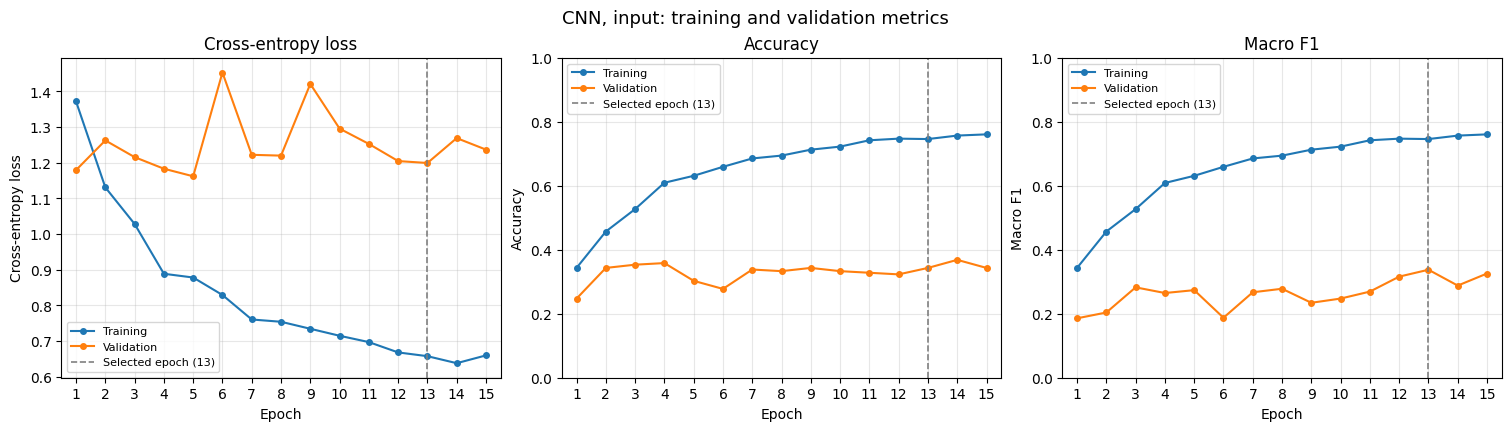

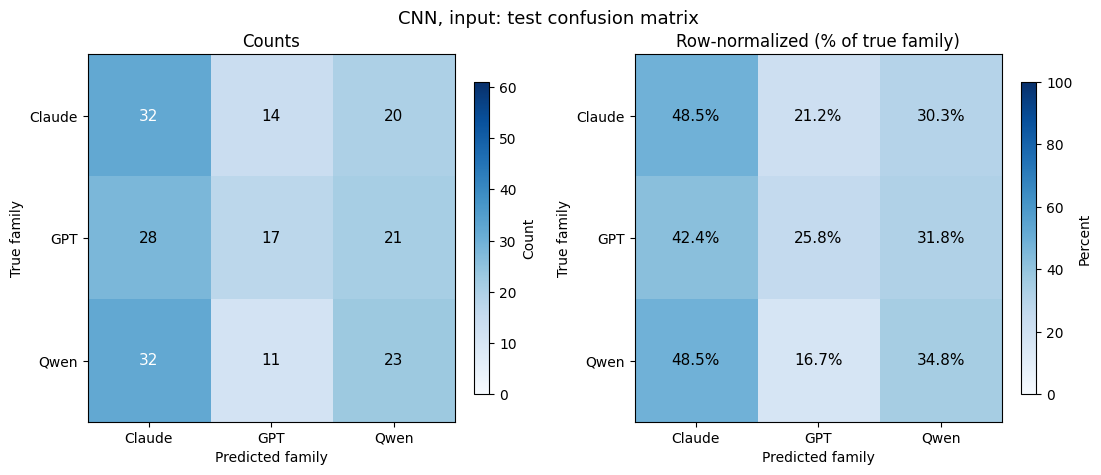

Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_training.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_training.pdf
Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_confusion.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_confusion.pdf


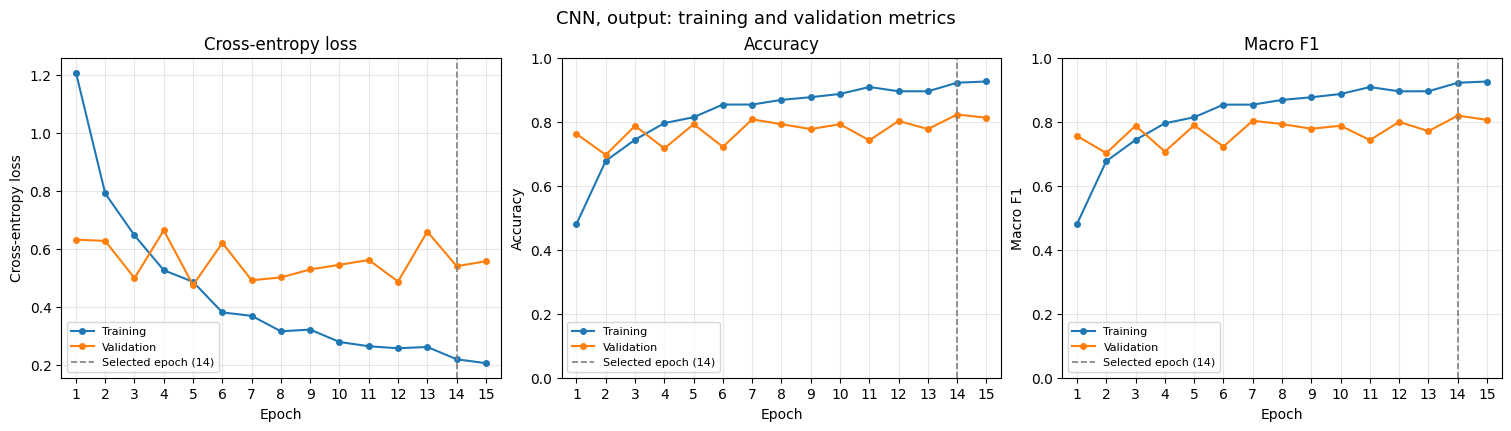

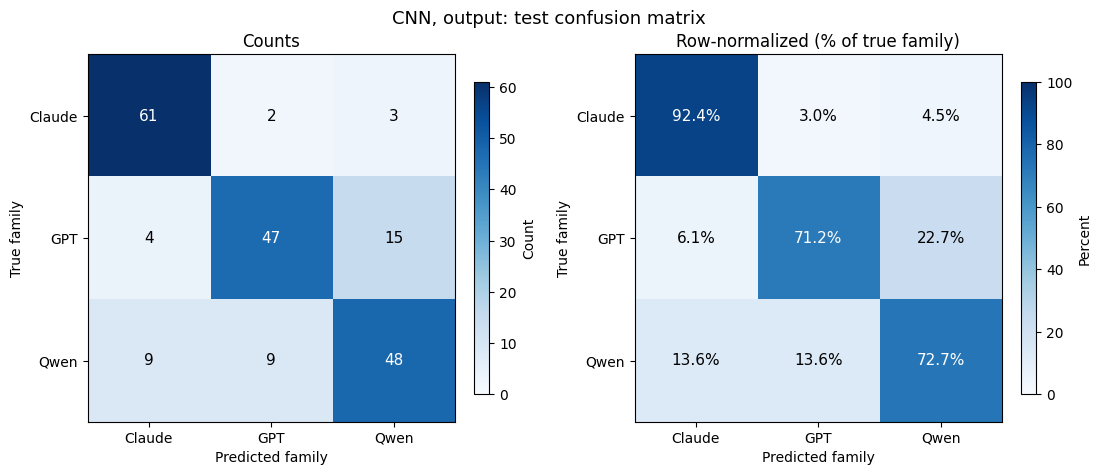

Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_output_training.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_output_training.pdf
Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_output_confusion.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_output_confusion.pdf


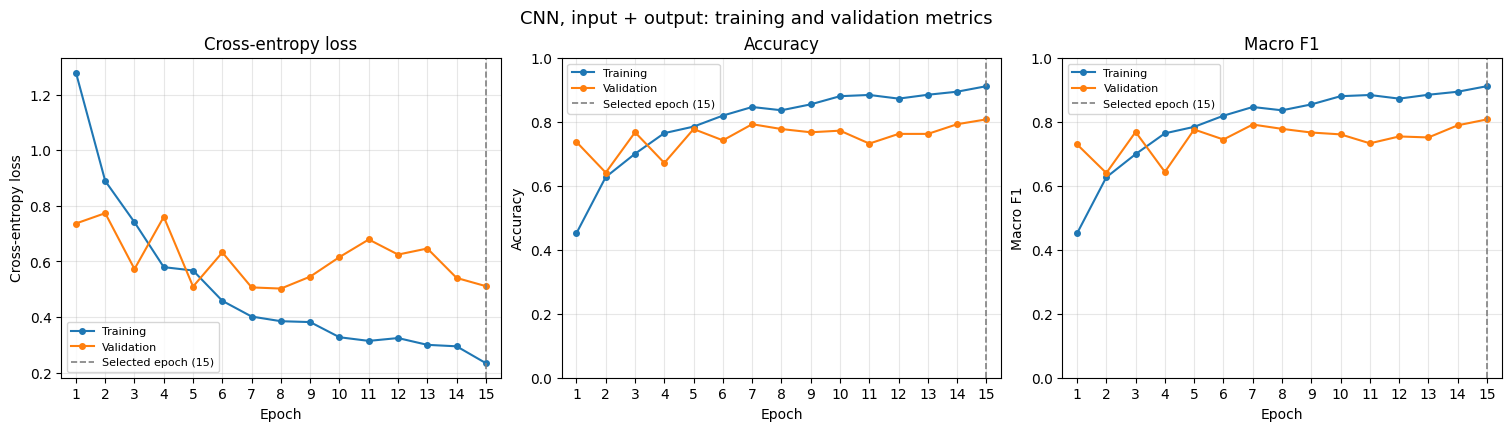

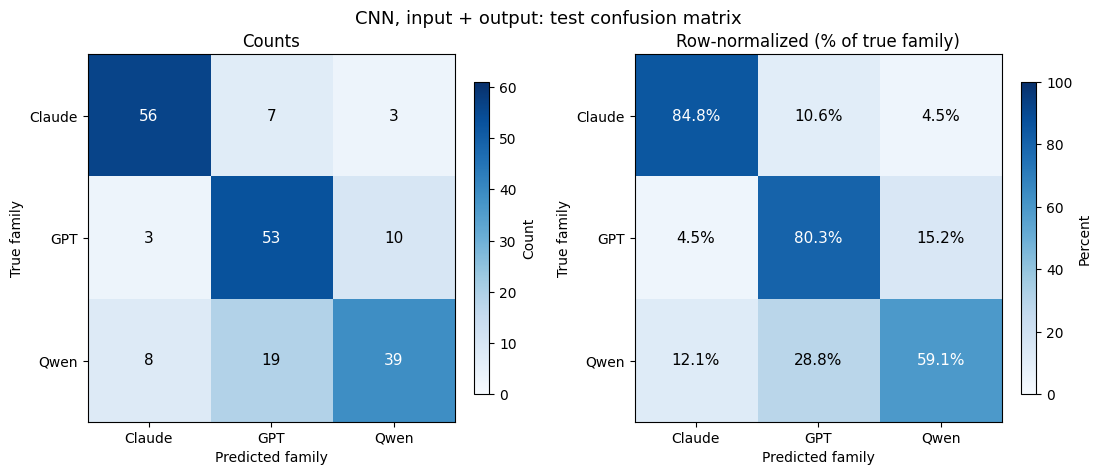

Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_plus_output_training.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_plus_output_training.pdf
Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_plus_output_confusion.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/CNN_input_plus_output_confusion.pdf


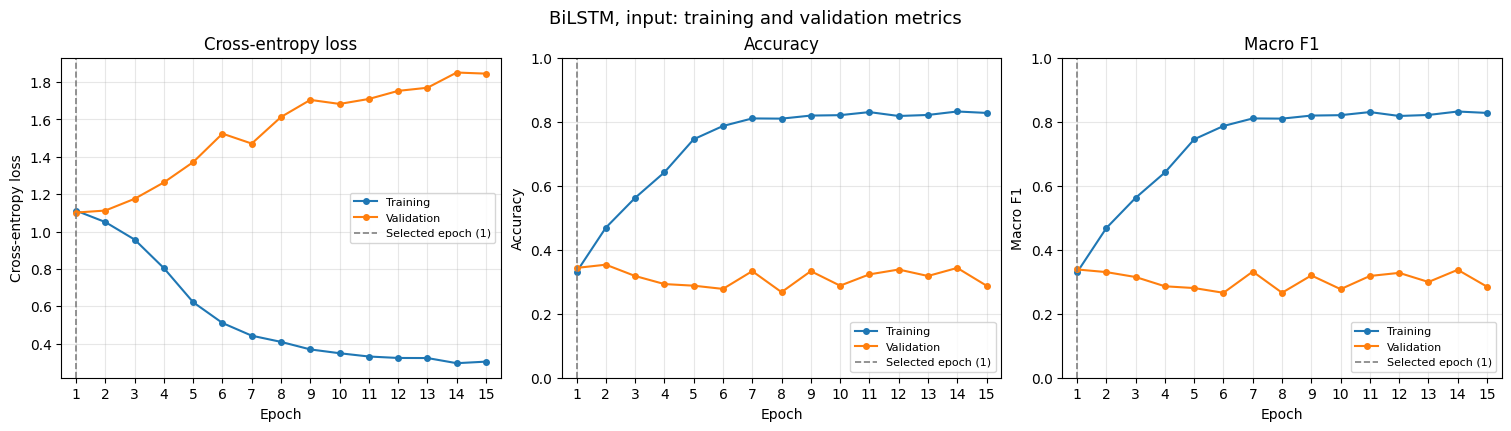

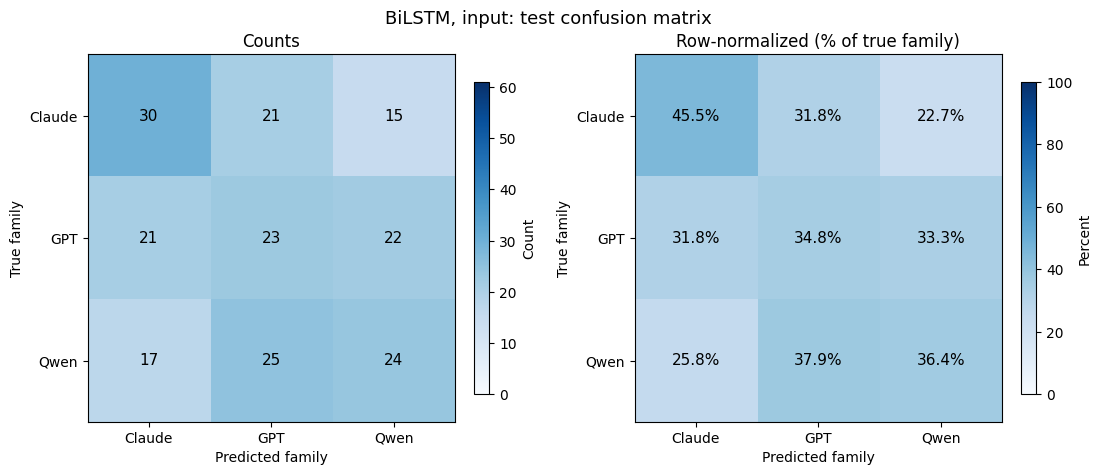

Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_training.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_training.pdf
Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_confusion.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_confusion.pdf


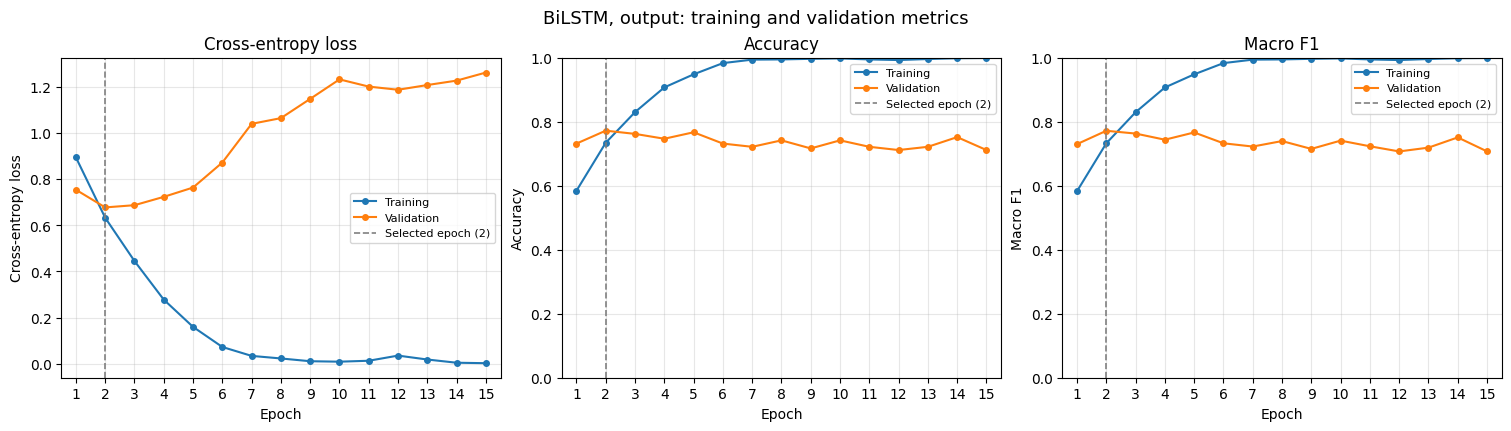

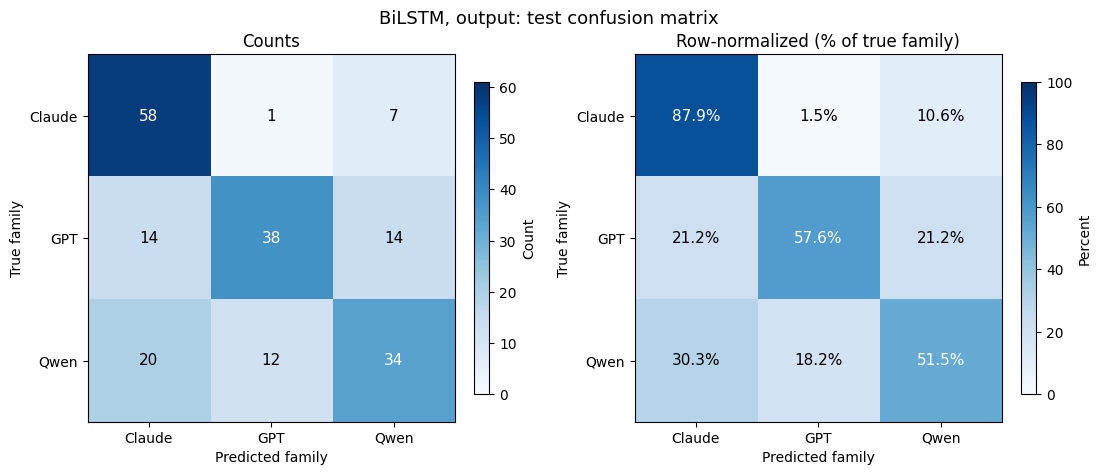

Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_output_training.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_output_training.pdf
Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_output_confusion.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_output_confusion.pdf


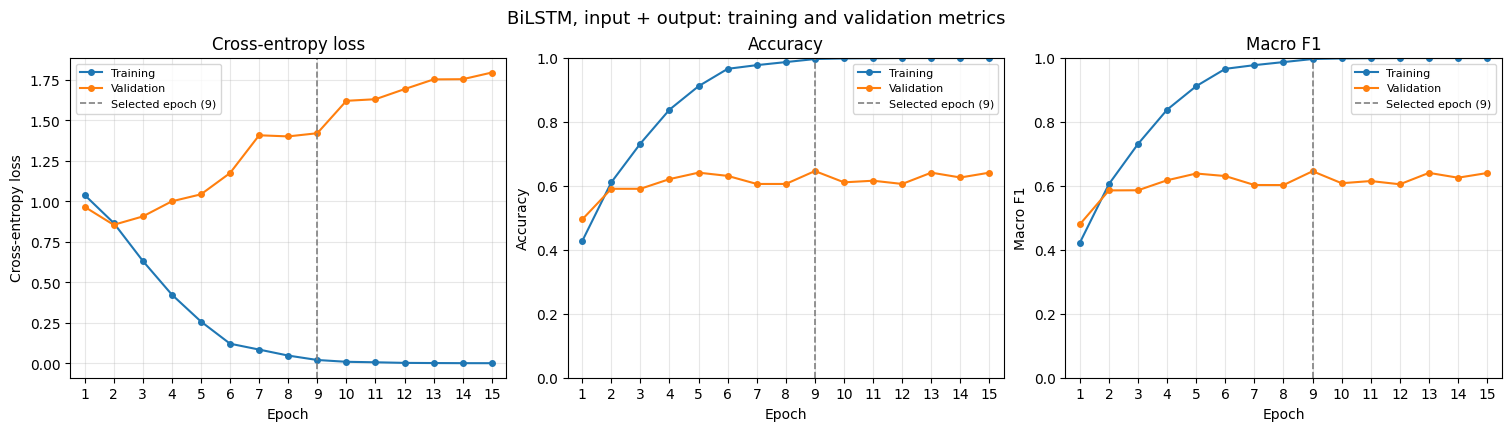

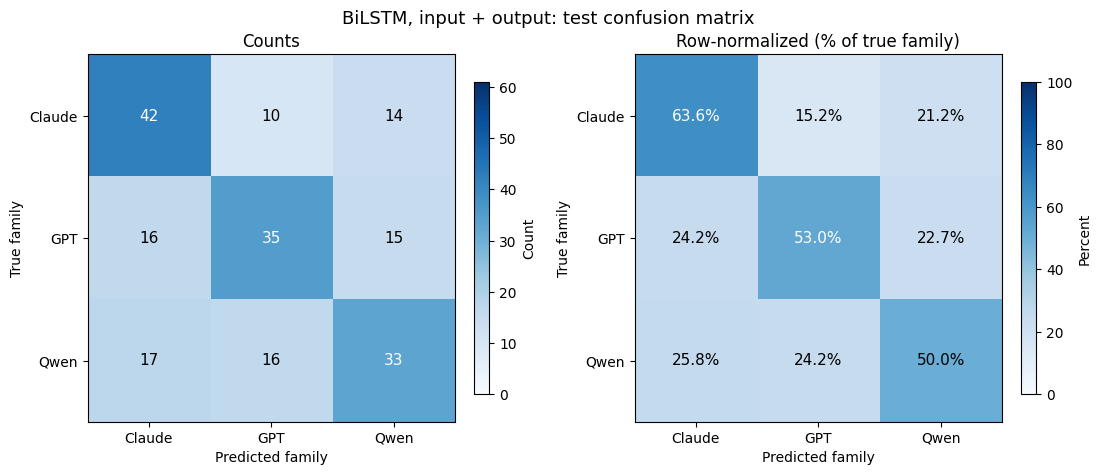

Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_plus_output_training.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_plus_output_training.pdf
Saved: /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_plus_output_confusion.png, /content/drive/MyDrive/CMPSC448_WhoWroteIt/figures/BiLSTM_input_plus_output_confusion.pdf


In [65]:
# Load and check all artifacts, then display and save both figures for each configuration
histories, cms, selected_epochs, test_size = load_plot_artifacts()
print(f"All artifacts present and consistent (test split size {test_size}).")
count_vmax = max(int(cm.values.max()) for cm in cms.values())     # shared color limit for count matrices

for model_name, condition in PLOT_CONFIGS:
    key, name = (model_name, condition), plot_run_name(model_name, condition)
    for fig, stem in [(plot_training(histories[key], model_name, condition, selected_epochs[key]), f"{name}_training"),
                      (plot_confusion(cms[key], model_name, condition, count_vmax), f"{name}_confusion")]:
        paths = save_figure(fig, stem)
        plt.show()
        plt.close(fig)
        print("Saved:", ", ".join(str(p) for p in paths))